# Proyecto 2 · Clustering con Machine Learning y Aplicación Web
## Segmentación de perfiles de productividad de desarrolladores (DevCare)

| | |
|---|---|
| **Asignatura** | Inteligencia Artificial · Sexto semestre · Ingeniería en Sistemas de Información (PUCE) |
| **Nombre** | Ariel Chacha |
| **Dataset** | ai_dev_productivity.csv · Kaggle · https://www.kaggle.com/datasets/atharvasoundankar/ai-developer-productivity-dataset |

**Contenido del notebook**

1. Contexto y pregunta de negocio
2. Configuración y carga de datos
3. Análisis exploratorio de datos (EDA)
4. Preparación de datos
5. Reducción de dimensionalidad con PCA
6. Modelado con K-Means
7. Modelado con DBSCAN
8. Evaluación y comparación de modelos
9. Interpretación de los segmentos
10. Entrenamiento final y exportación

## 1. Contexto y pregunta de negocio

Los equipos de desarrollo suelen recibir las mismas políticas de trabajo (horarios, herramientas, carga de tareas) aunque sus integrantes trabajen de formas muy distintas. Este proyecto busca segmentar perfiles de desarrolladores según sus hábitos de trabajo para que las decisiones de gestión se ajusten a cada grupo.

**Pregunta de negocio:** ¿qué perfiles de hábitos de trabajo existen entre los desarrolladores y qué intervención conviene a cada uno?

| Elemento | Descripción |
|---|---|
| **Qué se segmenta** | Registros de desarrolladores descritos por horas de programación, cafeína, distracciones, sueño, commits, bugs, uso de herramientas de IA y carga cognitiva |
| **Quién usa el resultado** | Líder técnico, *engineering manager* o área de talento humano |
| **Decisión que habilita** | Dirigir acciones distintas a cada segmento: bienestar y descanso, redistribución de carga, capacitación en herramientas de IA |
| **Costo de equivocarse** | Una intervención mal dirigida, por ejemplo aumentar la carga de alguien que ya está desgastado |

**Por qué es un problema no supervisado.** No existe una columna que diga a qué perfil pertenece cada desarrollador; los grupos se descubren a partir de la similitud entre registros. Por eso no hay variable objetivo y ni división en entrenamiento y prueba.

**Sobre task_success.** El dataset incluye esta columna binaria (0/1). Según la guía del proyecto, las variables binarias no entran al modelo. Se reserva únicamente para describir los segmentos al final (su promedio por grupo es la proporción de tareas exitosas).

## 2. Configuración y carga de datos

Se fija una semilla (SEED = 42) para que los resultados sean reproducibles y se imprimen las versiones de las librerías, porque el modelo exportado con joblib debe cargarse con la misma versión de scikit-learn.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42                     # semilla única para todo el proyecto
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)

pandas: 3.1.1 | numpy: 2.5.4 | scikit-learn: 1.9.1


In [2]:
# Se busca el CSV en las ubicaciones habituales (carpeta del proyecto, Colab o misma carpeta)
RUTAS = [Path("../data/ai_dev_productivity.csv"), Path("data/ai_dev_productivity.csv"), Path("ai_dev_productivity.csv")]
RUTA_DATOS = next((r for r in RUTAS if r.exists()), None)
if RUTA_DATOS is None:
    raise FileNotFoundError("No se encontró ai_dev_productivity.csv; colócalo en la carpeta data/")

df = pd.read_csv(RUTA_DATOS, encoding="utf-8-sig")   # utf-8-sig descarta la marca BOM del archivo
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
df.head()

Filas: 500 | Columnas: 9


,hours_coding,coffee_intake_mg,distractions,sleep_hours,commits,bugs_reported,ai_usage_hours,cognitive_load,task_success
0,5.99,600,1,5.8,2,1,0.71,5.4,1
1,4.72,568,2,6.9,5,3,1.75,4.7,1
2,6.30,560,1,8.9,2,0,2.27,2.2,1
3,8.05,600,7,6.3,9,5,1.40,5.9,0
4,4.53,421,6,6.9,4,0,1.26,6.3,1


## 3. Análisis exploratorio de datos (EDA)

### 3.1 Estructura, tipos, valores faltantes y duplicados

In [3]:
df.info()
print()
print("Valores nulos en total:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   hours_coding      500 non-null    float64
 1   coffee_intake_mg  500 non-null    int64  
 2   distractions      500 non-null    int64  
 3   sleep_hours       500 non-null    float64
 4   commits           500 non-null    int64  
 5   bugs_reported     500 non-null    int64  
 6   ai_usage_hours    500 non-null    float64
 7   cognitive_load    500 non-null    float64
 8   task_success      500 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 35.3 KB

Valores nulos en total: 0
Filas duplicadas: 0


In [4]:
# Las variables con solo dos valores distintos son binarias: se identifican para excluirlas del modelo
NUMERICAS = [c for c in df.columns if df[c].nunique() > 2]
BINARIAS = [c for c in df.columns if df[c].nunique() == 2]

print("Numéricas no binarias (", len(NUMERICAS), "):", NUMERICAS)
print("Binarias (", len(BINARIAS), "):", BINARIAS)

Numéricas no binarias ( 8 ): ['hours_coding', 'coffee_intake_mg', 'distractions', 'sleep_hours', 'commits', 'bugs_reported', 'ai_usage_hours', 'cognitive_load']
Binarias ( 1 ): ['task_success']


**Lectura.** El dataset tiene 500 registros y 9 columnas, todas numéricas, sin valores nulos ni filas duplicadas. No hace falta imputación. Hay 8 variables numéricas no binarias (la guía exige al menos 5) y una binaria, task_success.

| Variable | Significado | Tipo |
|---|---|---|
| hours_coding | Horas dedicadas a programar | Continua |
| coffee_intake_mg | Cafeína consumida, en miligramos | Continua |
| distractions | Número de distracciones | Discreta |
| sleep_hours | Horas de sueño | Continua |
| commits | Número de commits | Discreta |
| bugs_reported | Número de bugs reportados | Discreta |
| ai_usage_hours | Horas de uso de herramientas de IA | Continua |
| cognitive_load | Carga cognitiva percibida (escala 1–10) | Continua |
| task_success | Tarea completada con éxito (0/1) | Binaria, fuera del modelo |

### 3.2 Estadísticas descriptivas

In [5]:
resumen = df[NUMERICAS].describe().T
resumen["asimetria"] = df[NUMERICAS].skew()
resumen["valores_distintos"] = df[NUMERICAS].nunique()
resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,valores_distintos
hours_coding,500.0,5.02,1.95,0.0,3.60,5.03,6.28,12.00,0.20,353
coffee_intake_mg,500.0,463.19,142.33,6.0,369.50,500.50,600.00,600.00,-0.91,244
distractions,500.0,2.98,1.68,0.0,2.00,3.00,4.00,8.00,0.50,9
sleep_hours,500.0,6.98,1.46,3.0,6.10,6.95,7.90,10.00,-0.14,67
commits,500.0,4.61,2.70,0.0,3.00,5.00,6.00,13.00,0.30,14
bugs_reported,500.0,0.86,1.10,0.0,0.00,0.00,2.00,5.00,1.25,6
ai_usage_hours,500.0,1.51,1.09,0.0,0.70,1.26,2.07,6.36,1.21,260
cognitive_load,500.0,4.50,1.87,1.0,3.18,4.40,5.80,10.00,0.18,79


**Lectura.**

- **Las escalas son muy distintas.** coffee_intake_mg llega a 600 con una desviación estándar de 142, mientras que el resto de variables se mueve entre 0 y 13. Sin escalar, la distancia euclidiana quedaría dominada por la cafeína (se cuantifica en la sección 4.2).
- **coffee_intake_mg tiene un tope.** El máximo (600) coincide con el tercer cuartil: al menos el 25 % de los registros vale exactamente 600. Se revisa en la sección 3.4.
- **bugs_reported es muy asimétrica.** Su mediana es 0: más de la mitad de los registros no reporta bugs.

### 3.3 Visualización 1 · Distribución de cada variable

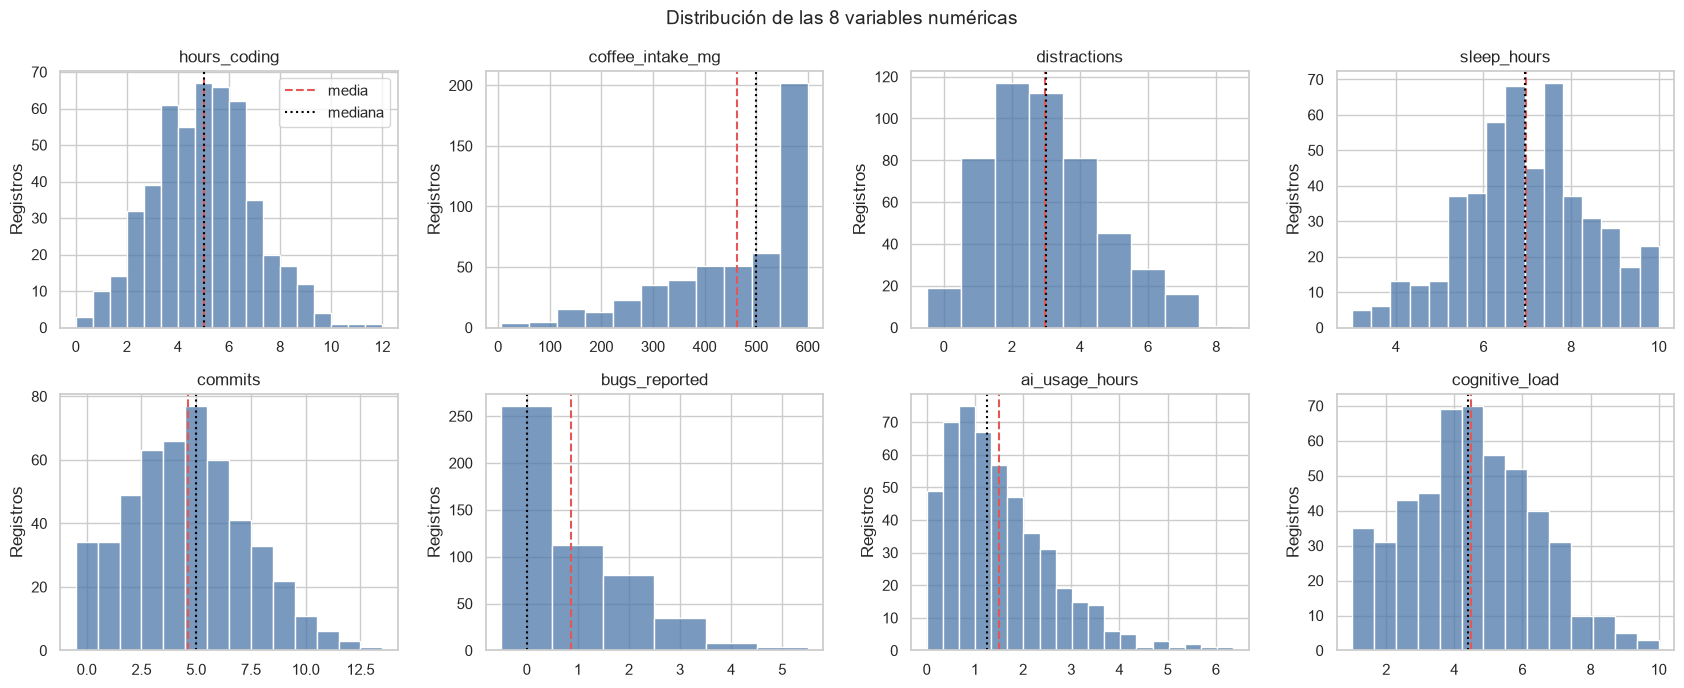

In [6]:
DISCRETAS = ["distractions", "commits", "bugs_reported"]     # conteos enteros: una barra por valor

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), NUMERICAS):
    sns.histplot(df[col], ax=ax, discrete=(col in DISCRETAS), bins="auto", color="#4C78A8")
    ax.axvline(df[col].mean(), color="#E45756", linestyle="--", linewidth=1.5, label="media")
    ax.axvline(df[col].median(), color="black", linestyle=":", linewidth=1.5, label="mediana")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Registros")
axes[0, 0].legend()
fig.suptitle("Distribución de las 8 variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación.**

- hours_coding, sleep_hours y cognitive_load tienen forma aproximadamente acampanada y simétrica (media y mediana casi coinciden).
- coffee_intake_mg muestra una barra muy alta en 600: la distribución está cortada por la derecha.
- ai_usage_hours y bugs_reported tienen cola a la derecha: la mayoría usa poca IA y reporta pocos bugs, y unos pocos registros toman valores altos.
- distractions, commits y bugs_reported son conteos enteros. En los gráficos de dispersión formarán bandas, lo cual es propio de su naturaleza discreta.

Ninguna variable muestra dos "montañas" separadas. Es una primera señal de que los datos forman una nube continua y no grupos aislados, algo que condicionará los resultados de DBSCAN.

### 3.4 Valores concentrados: el tope de cafeína y los ceros

In [7]:
tope = df["coffee_intake_mg"].max()
n_tope = (df["coffee_intake_mg"] == tope).sum()
print(f"coffee_intake_mg: {n_tope} registros ({n_tope / len(df):.1%}) valen exactamente {tope} (el máximo)")

ceros = (df[DISCRETAS] == 0).sum().to_frame("registros_en_cero")
ceros["porcentaje"] = (ceros["registros_en_cero"] / len(df) * 100).round(1)
ceros

coffee_intake_mg: 145 registros (29.0%) valen exactamente 600 (el máximo)


,registros_en_cero,porcentaje
distractions,19,3.8
commits,34,6.8
bugs_reported,261,52.2


**Lectura.**

- **Tope de 600 mg.** Casi un tercio de la muestra comparte exactamente el valor máximo. Un pico así en el extremo de una distribución no es un conjunto de valores atípicos, sino la huella de un valor censurado por la derecha: el dato real puede ser mayor, pero quedó registrado como 600. Se analiza en detalle en la sección 3.4.1.
- **Ceros en bugs_reported.** Más de la mitad de los registros no tiene bugs. La variable aporta información sobre todo para distinguir al grupo que sí los tiene.

#### 3.4.1 ¿Qué información se pierde con el tope de 600 mg?

Si el tope fuera aleatorio, afectaría por igual a cualquier tipo de registro. La siguiente celda comprueba si, por el contrario, depende de la intensidad de trabajo.

In [8]:
en_tope = df["coffee_intake_mg"] == tope

# 1) ¿En qué jornadas aparece el tope? Porcentaje de registros en 600 mg por tramo de horas de programación
tramos = pd.cut(df["hours_coding"], bins=[-0.01, 3, 4, 5, 6, 7, 8, 12])
por_tramo = df.groupby(tramos, observed=True).agg(registros=("coffee_intake_mg", "size"),
                                                  pct_en_tope=("coffee_intake_mg", lambda s: (s == tope).mean() * 100))
display(por_tramo.round(1))

# 2) Relación horas–cafeína con y sin los registros censurados
r_total = df["hours_coding"].corr(df["coffee_intake_mg"])
r_sin_tope = df.loc[~en_tope, "hours_coding"].corr(df.loc[~en_tope, "coffee_intake_mg"])
print(f"Correlación horas–cafeína: con todos = {r_total:.3f} | sin los registros en el tope = {r_sin_tope:.3f}")

# 3) Consumo "latente" aproximado: la recta ajustada en los registros no censurados, extrapolada a los censurados
pendiente, intercepto = np.polyfit(df.loc[~en_tope, "hours_coding"], df.loc[~en_tope, "coffee_intake_mg"], deg=1)
latente = pendiente * df.loc[en_tope, "hours_coding"] + intercepto
print(f"Recta en no censurados: cafeína ≈ {pendiente:.1f} · horas + {intercepto:.1f}")
print(f"En los {en_tope.sum()} registros censurados, la recta estima una mediana de {latente.median():.0f} mg "
      f"y el {(latente > tope).mean():.0%} superaría los {tope} mg")

# 4) Dónde queda el tope después de escalar
z_tope = (tope - df["coffee_intake_mg"].mean()) / df["coffee_intake_mg"].std(ddof=0)
print(f"Tras StandardScaler, los {en_tope.sum()} registros comparten el mismo valor z = {z_tope:.2f} en esta variable")

,registros,pct_en_tope
hours_coding,,
"(-0.01, 3.0]",76,0.0
"(3.0, 4.0]",84,0.0
"(4.0, 5.0]",86,0.0
"(5.0, 6.0]",102,10.8
"(6.0, 7.0]",81,77.8
"(7.0, 8.0]",36,100.0
"(8.0, 12.0]",35,100.0


Correlación horas–cafeína: con todos = 0.890 | sin los registros en el tope = 0.935
Recta en no censurados: cafeína ≈ 91.8 · horas + 31.7
En los 145 registros censurados, la recta estima una mediana de 670 mg y el 86% superaría los 600 mg
Tras StandardScaler, los 145 registros comparten el mismo valor z = 0.96 en esta variable


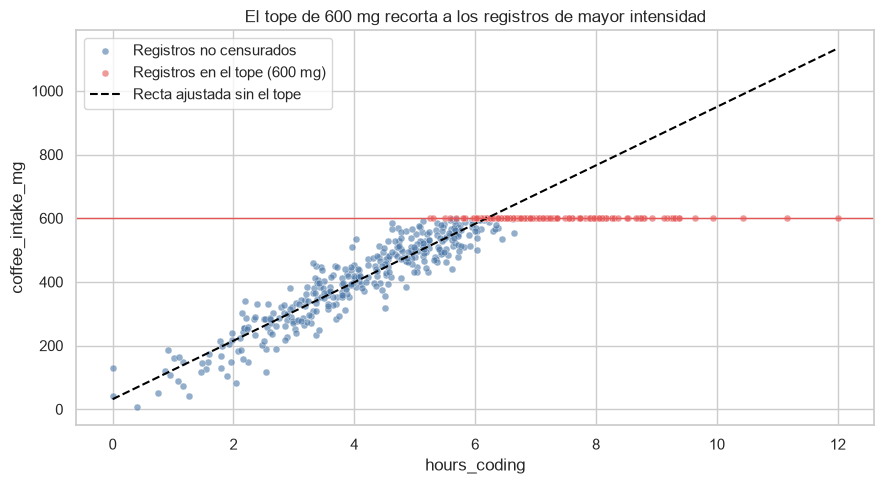

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(x=df.loc[~en_tope, "hours_coding"], y=df.loc[~en_tope, "coffee_intake_mg"], s=25, alpha=0.6,
                color="#4C78A8", label="Registros no censurados", ax=ax)
sns.scatterplot(x=df.loc[en_tope, "hours_coding"], y=df.loc[en_tope, "coffee_intake_mg"], s=25, alpha=0.6,
                color="#E45756", label=f"Registros en el tope ({tope} mg)", ax=ax)
horas = np.linspace(0, df["hours_coding"].max(), 100)
ax.plot(horas, pendiente * horas + intercepto, color="black", linestyle="--", label="Recta ajustada sin el tope")
ax.axhline(tope, color="#E45756", linewidth=1)
ax.set_xlabel("hours_coding")
ax.set_ylabel("coffee_intake_mg")
ax.set_title("El tope de 600 mg recorta a los registros de mayor intensidad")
ax.legend()
plt.tight_layout()
plt.show()

**Justificación técnica del tratamiento del tope.**

**Diagnóstico.** El tope no es aleatorio: no aparece en jornadas de hasta 5 horas, aparece en una minoría entre 5 y 6 horas y en todos los registros desde las 7 horas. Es una censura sistemática que afecta solo al grupo de mayor intensidad. Sin esos registros la relación horas–cafeína es casi lineal, y al extrapolar esa recta la mayoría de los registros censurados tendría un consumo real superior a 600 mg.

**Consecuencias para el clustering:**

1. En la dimensión de cafeína, los 145 registros censurados son indistinguibles entre sí: todos quedan en el mismo valor z. Esa variable discrimina bien entre intensidad baja y media, pero no dentro del grupo de intensidad alta.
2. La información que se pierde sí se conserva en otra variable. hours_coding no está censurada (llega a 12 horas) y se correlaciona fuertemente con la cafeína, de modo que la intensidad de trabajo del grupo alto sigue medida por las horas, los commits y el uso de IA.
3. El promedio de cafeína de un segmento intensivo será una cota inferior del consumo real. Debe leerse como "600 mg o más", no como el valor exacto.

**Alternativas evaluadas:**

| Alternativa | Ventaja | Por qué se descarta |
|---|---|---|
| Eliminar coffee_intake_mg | Elimina la redundancia con hours_coding | Pierde la capacidad de separar consumo bajo y medio, donde la variable sí es informativa |
| Eliminar los 145 registros en el tope | Quita la masa puntual | Elimina el 29 % de la muestra y justo a los desarrolladores más intensivos: sesgaría la segmentación |
| Imputar el valor latente con la recta | Recupera una escala continua | Inventa datos; además, la imputación se calcularía con hours_coding y solo repetiría esa variable |
| Añadir un indicador binario "en el tope" | Marca explícitamente la censura | La guía prohíbe que las variables binarias entren al modelo |
| Conservar la variable tal como está | Usa el dato real sin manipularlo; la intensidad del grupo alto la recogen las demás variables | Costo asumido: masa puntual en una dimensión y perfil de cafeína del grupo alto subestimado |

**Decisión:** se conserva coffee_intake_mg sin transformar. La censura se documenta como limitación del dataset, el perfil de cafeína de los segmentos intensivos se interpretará como "600 mg o más", y en la aplicación web el campo de cafeína admitirá como máximo 600 mg, porque el modelo nunca vio valores superiores.

### 3.5 Visualización 2 · Valores atípicos (outliers)

Se usa la regla del rango intercuartílico (IQR = Q3 − Q1, el ancho de la caja): un valor es atípico si se aleja más de 1.5 veces ese ancho por debajo de Q1 o por encima de Q3.

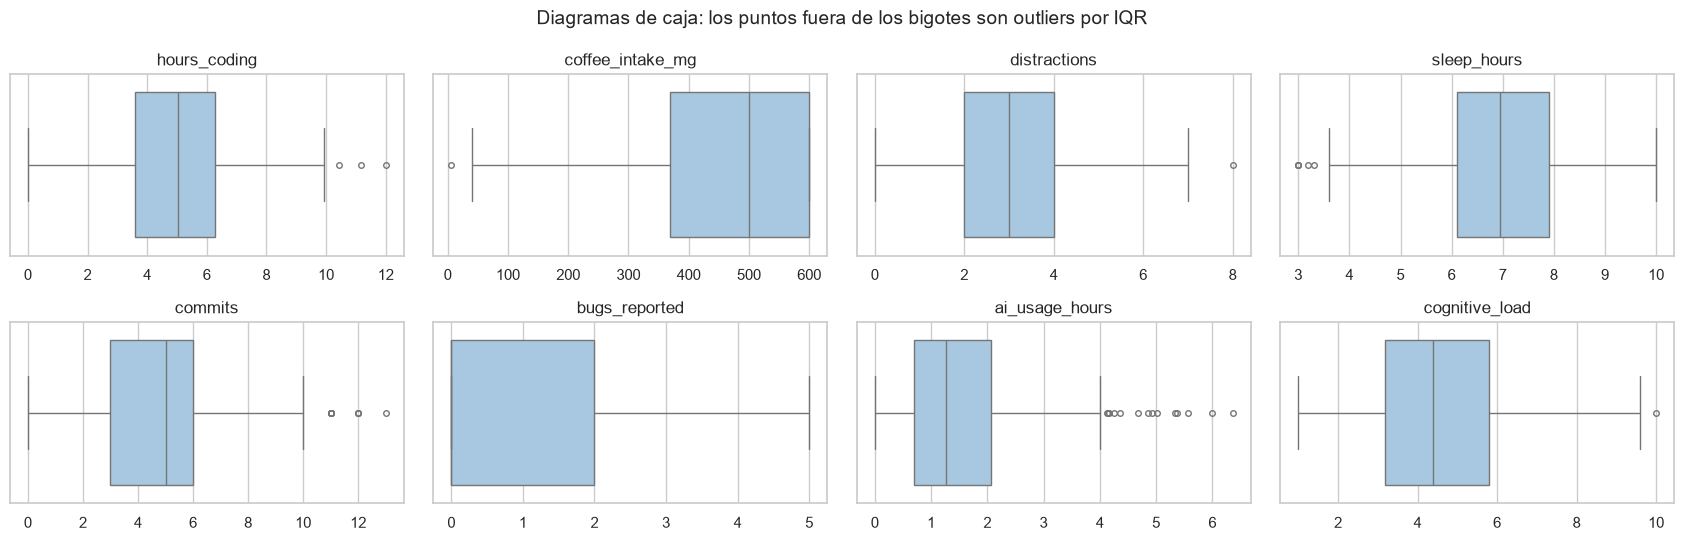

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(17, 5.5))
for ax, col in zip(axes.ravel(), NUMERICAS):
    sns.boxplot(x=df[col], ax=ax, color="#9ECAE9", fliersize=4)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Diagramas de caja: los puntos fuera de los bigotes son outliers por IQR", fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
datos = df[NUMERICAS]
q1, q3 = datos.quantile(0.25), datos.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
es_outlier = (datos < lim_inf) | (datos > lim_sup)

tabla_outliers = pd.DataFrame({
    "limite_inferior": lim_inf,
    "limite_superior": lim_sup,
    "n_outliers": es_outlier.sum(),
    "porcentaje": es_outlier.mean() * 100,
    "z_maximo": ((datos - datos.mean()) / datos.std(ddof=0)).abs().max(),   # cuántas desviaciones se aleja el valor más extremo
})
print("Registros con al menos un valor atípico:", es_outlier.any(axis=1).sum(), "de", len(df))
tabla_outliers.round(2)

Registros con al menos un valor atípico: 30 de 500


,limite_inferior,limite_superior,n_outliers,porcentaje,z_maximo
hours_coding,-0.41,10.29,3,0.6,3.59
coffee_intake_mg,23.75,945.75,1,0.2,3.22
distractions,-1.00,7.00,1,0.2,3.00
sleep_hours,3.40,10.60,5,1.0,2.73
commits,-1.50,10.50,10,2.0,3.11
bugs_reported,-3.00,5.00,0,0.0,3.76
ai_usage_hours,-1.36,4.13,14,2.8,4.47
cognitive_load,-0.76,9.74,1,0.2,2.95


In [12]:
# Efecto de los outliers sobre un promedio: un centroide de K-Means es exactamente un promedio
col = "ai_usage_hours"
media_con = df[col].mean()
media_sin = df.loc[~es_outlier[col], col].mean()
print(f"Media de {col} con outliers: {media_con:.3f}")
print(f"Media de {col} sin outliers: {media_sin:.3f}")
print(f"Desplazamiento causado por {es_outlier[col].sum()} registros ({es_outlier[col].mean():.1%}): {media_con - media_sin:.3f} horas")

Media de ai_usage_hours con outliers: 1.511
Media de ai_usage_hours sin outliers: 1.412
Desplazamiento causado por 14 registros (2.8%): 0.099 horas


**Interpretación y decisión.**

- Los outliers son pocos: la variable con más casos es ai_usage_hours, seguida de commits y sleep_hours. Todos son valores posibles en la realidad (jornadas de 12 horas, 13 commits, 3 horas de sueño), no errores de captura.
- **Cómo afectan a K-Means.** El centroide de cada grupo es un promedio, y K-Means busca que los puntos queden lo más cerca posible de su centroide midiendo la distancia al cuadrado. Por eso un punto muy lejano pesa mucho más que uno cercano y arrastra al centroide hacia él. La celda anterior lo muestra con un promedio simple: un pequeño porcentaje de registros desplaza la media de ai_usage_hours.
- **Cómo afectan a DBSCAN.** DBSCAN no usa centroides; los puntos aislados quedan etiquetados como ruido (−1) sin deformar los grupos.
- **Decisión: se conservan.** Son perfiles reales y extremos, justo los que interesa identificar, y eliminarlos reduciría una muestra de solo 500 registros. Su influencia se controla con el escalado, y en la sección 8.4 se comprueba que eliminarlos apenas cambiaría la segmentación.

### 3.6 Visualización 3 · Correlaciones

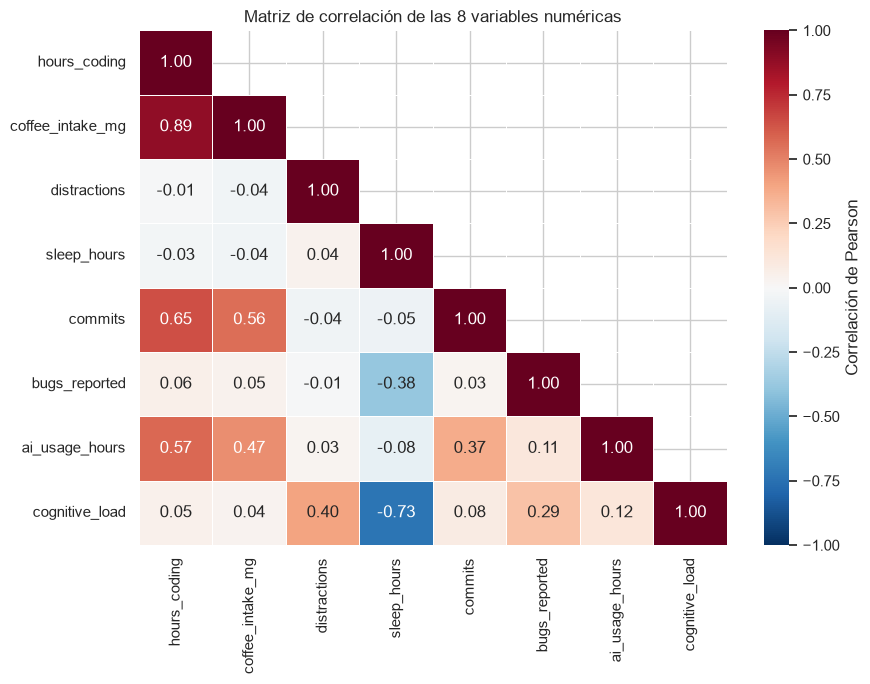

In [13]:
corr = df[NUMERICAS].corr()

plt.figure(figsize=(9, 7))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)       # oculta el triángulo superior (es simétrico)
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={"label": "Correlación de Pearson"})
plt.title("Matriz de correlación de las 8 variables numéricas")
plt.tight_layout()
plt.show()

In [14]:
# Pares más correlacionados (en valor absoluto)
pares = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack().rename("correlacion")
pares.reindex(pares.abs().sort_values(ascending=False).index).head(8).round(2).to_frame()

,,correlacion
coffee_intake_mg,hours_coding,0.89
cognitive_load,sleep_hours,-0.73
commits,hours_coding,0.65
ai_usage_hours,hours_coding,0.57
commits,coffee_intake_mg,0.56
ai_usage_hours,coffee_intake_mg,0.47
cognitive_load,distractions,0.40
bugs_reported,sleep_hours,-0.38


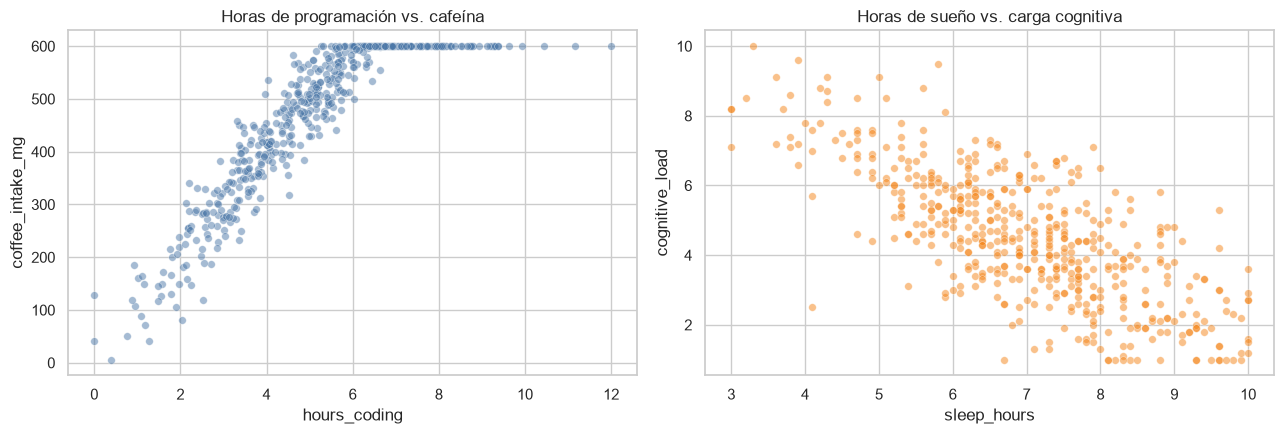

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="hours_coding", y="coffee_intake_mg", alpha=0.5, s=30, color="#4C78A8", ax=axes[0])
axes[0].set_title("Horas de programación vs. cafeína")
sns.scatterplot(data=df, x="sleep_hours", y="cognitive_load", alpha=0.5, s=30, color="#F58518", ax=axes[1])
axes[1].set_title("Horas de sueño vs. carga cognitiva")
plt.tight_layout()
plt.show()

**Interpretación.** Las correlaciones revelan dos bloques de variables casi independientes entre sí:

1. **Intensidad de trabajo:** hours_coding, coffee_intake_mg, commits y ai_usage_hours suben juntas. La relación entre horas y cafeína es tan fuerte (0.89) que casi miden lo mismo; en el gráfico se ve además la franja horizontal del tope de 600 mg.
2. **Descanso frente a desgaste:** sleep_hours y cognitive_load se mueven en sentidos opuestos (−0.73): a menos sueño, más carga cognitiva. bugs_reported y distractions acompañan a la carga cognitiva.

Entre ambos bloques las correlaciones son cercanas a cero: saber cuántas horas programa alguien no dice casi nada sobre cuánto duerme.

**Implicaciones para lo que sigue:**

- Hay redundancia, así que PCA debería resumir buena parte de la información en pocas componentes, una por bloque.
- En la distancia euclidiana, dos variables muy correlacionadas (horas y cafeína) hacen que el mismo factor pese dos veces. Se tendrá en cuenta al decidir sobre qué espacio entrenar (sección 5.4).

## 4. Preparación de datos

### 4.1 Selección de variables

- **Entran a X:** las 8 variables numéricas no binarias.
- **Queda fuera:** task_success, por ser binaria. Se guarda aparte y no participa en el escalado, en PCA ni en la elección de hiperparámetros. Solo se usará al final para describir los segmentos.
- No hay identificadores ni variables categóricas de texto que excluir, ni valores faltantes que imputar.

In [16]:
VARIABLES = ["hours_coding", "coffee_intake_mg", "distractions", "sleep_hours",
             "commits", "bugs_reported", "ai_usage_hours", "cognitive_load"]

X = df[VARIABLES].copy()                 # entrada de los modelos, en escala original
exito = df["task_success"].copy()        # reservada: solo para interpretar los segmentos

assert set(VARIABLES) == set(NUMERICAS), "X debe contener exactamente las numéricas no binarias"
assert "task_success" not in X.columns
print("Forma de X:", X.shape, "| D (número de variables) =", X.shape[1])

Forma de X: (500, 8) | D (número de variables) = 8


### 4.2 Escalado con StandardScaler

K-Means, DBSCAN y PCA trabajan con distancias y varianzas, que dependen de las unidades de cada variable. StandardScaler lleva todas las variables a la misma escala: a cada valor le resta la media de su variable y lo divide por la desviación estándar.

Cada variable queda con media 0 y desviación estándar 1, de modo que una diferencia de "una desviación estándar" pesa lo mismo en cualquiera de ellas. La siguiente celda muestra qué pasaría sin escalar.

In [17]:
# Sin escalar: qué porcentaje de la varianza total aporta cada variable
varianza_original = X.var(ddof=0)
(varianza_original / varianza_original.sum() * 100).round(2).to_frame("% de la varianza total (sin escalar)")

,% de la varianza total (sin escalar)
hours_coding,0.02
coffee_intake_mg,99.89
distractions,0.01
sleep_hours,0.01
commits,0.04
bugs_reported,0.01
ai_usage_hours,0.01
cognitive_load,0.02


In [18]:
escalador = StandardScaler()
X_esc = pd.DataFrame(escalador.fit_transform(X), columns=VARIABLES)   # para explorar; los modelos usarán Pipeline

comprobacion = pd.DataFrame({"media": X_esc.mean(), "desv_estandar": X_esc.std(ddof=0)})
comprobacion.round(3)

,media,desv_estandar
hours_coding,-0.0,1.0
coffee_intake_mg,-0.0,1.0
distractions,-0.0,1.0
sleep_hours,-0.0,1.0
commits,0.0,1.0
bugs_reported,-0.0,1.0
ai_usage_hours,-0.0,1.0
cognitive_load,0.0,1.0


**Lectura.**

- Sin escalar, coffee_intake_mg concentra prácticamente toda la varianza por estar medida en cientos de miligramos. K-Means agruparía solo por cafeína y PCA devolvería esa variable como primera componente. Por eso el escalado es obligatorio.
- Tras escalar, las 8 variables tienen media 0 y desviación estándar 1.

**Sobre la fuga de datos.** En aprendizaje supervisado el escalador se ajusta solo con el conjunto de entrenamiento. En clustering no hay división entrenamiento/prueba: el escalador se ajusta con el 100 % de los datos. Lo que sí se cuida es que la aplicación web reutilice este mismo escalador ya ajustado y nunca lo vuelva a ajustar con el registro nuevo. Para garantizarlo, los modelos se construyen dentro de un Pipeline, que es el objeto que se exportará.

## 5. Reducción de dimensionalidad con PCA

El Análisis de Componentes Principales resume las 8 variables en nuevas variables llamadas componentes. Cada componente es una mezcla de las variables originales; la primera recoge la mayor parte posible de la variación de los datos, la segunda la mayor parte de lo que queda, y así sucesivamente. Las componentes no están correlacionadas entre sí.

- Los loadings indican cuánto pesa cada variable original en cada componente; sirven para ponerle nombre.
- La varianza explicada indica qué porcentaje de la información total recoge cada componente.
- El valor propio es esa misma varianza en unidades absolutas: mayor que 1 significa que la componente resume más que una variable original sola.

En este proyecto PCA cumple dos funciones: entender la estructura de los datos y obtener un mapa 2D donde visualizar los clusters.

### 5.1 Varianza explicada

In [19]:
pca_pipe = Pipeline([("escalar", StandardScaler()),
                     ("pca", PCA(random_state=SEED))])       # sin n_components: conserva las 8 componentes
pca_pipe.fit(X)                                              # X sin escalar: el Pipeline escala
pca = pca_pipe.named_steps["pca"]

nombres_pc = [f"PC{i + 1}" for i in range(pca.n_components_)]
varianza = pd.DataFrame({
    "valor_propio": pca.explained_variance_,
    "varianza_explicada": pca.explained_variance_ratio_,
    "varianza_acumulada": pca.explained_variance_ratio_.cumsum(),
}, index=nombres_pc)
varianza.round(3)

,valor_propio,varianza_explicada,varianza_acumulada
PC1,2.839,0.354,0.354
PC2,1.991,0.248,0.603
PC3,1.118,0.140,0.742
PC4,0.743,0.093,0.835
PC5,0.618,0.077,0.912
PC6,0.471,0.059,0.971
PC7,0.143,0.018,0.988
PC8,0.093,0.012,1.000


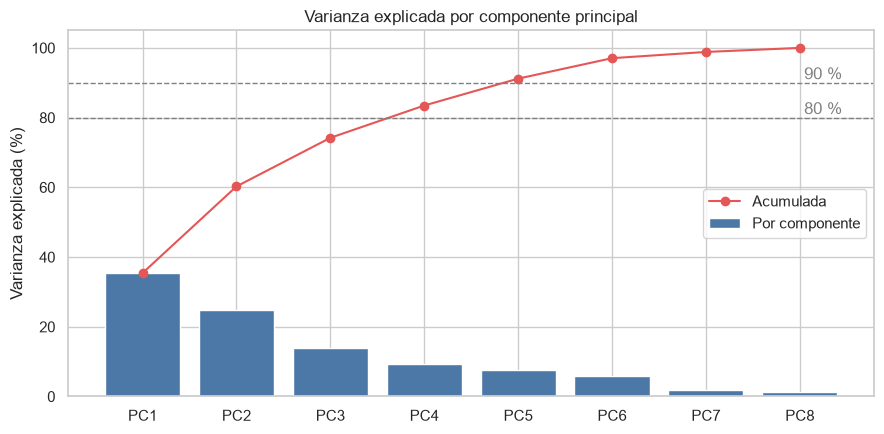

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(nombres_pc, varianza["varianza_explicada"] * 100, color="#4C78A8", label="Por componente")
ax.plot(nombres_pc, varianza["varianza_acumulada"] * 100, color="#E45756", marker="o", label="Acumulada")
for umbral in (80, 90):
    ax.axhline(umbral, color="gray", linestyle="--", linewidth=1)
    ax.text(len(nombres_pc) - 0.55, umbral + 1, f"{umbral} %", color="gray", ha="right")
ax.set_ylabel("Varianza explicada (%)")
ax.set_title("Varianza explicada por componente principal")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

**Interpretación.**

- PC1 recoge alrededor del 35 % de la varianza y PC2 cerca del 25 %: juntas, el 60 %. El mapa 2D muestra la mayor parte de la estructura, pero deja fuera casi un 40 %.
- Tres componentes tienen valor propio mayor que 1, es decir, cada una explica más que una variable original por sí sola.
- Para superar el 80 % hacen falta 4 componentes y para superar el 90 %, 5. La reducción a 2 dimensiones es útil para visualizar, pero no es una representación fiel de las 8 variables.

### 5.2 Loadings: qué significa cada componente

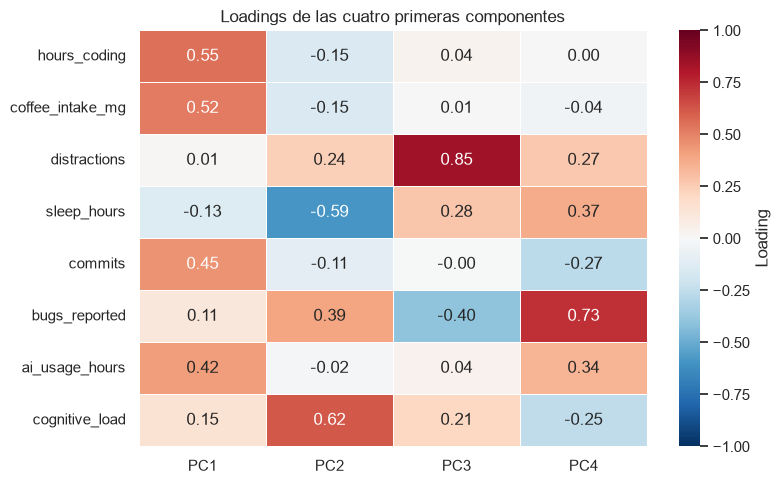

,PC1,PC2,PC3,PC4
hours_coding,0.55,-0.15,0.04,0.00
coffee_intake_mg,0.52,-0.15,0.01,-0.04
distractions,0.01,0.24,0.85,0.27
sleep_hours,-0.13,-0.59,0.28,0.37
commits,0.45,-0.11,-0.00,-0.27
bugs_reported,0.11,0.39,-0.40,0.73
ai_usage_hours,0.42,-0.02,0.04,0.34
cognitive_load,0.15,0.62,0.21,-0.25


In [21]:
loadings = pd.DataFrame(pca.components_.T, index=VARIABLES, columns=nombres_pc)

plt.figure(figsize=(8, 5))
sns.heatmap(loadings.iloc[:, :4], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Loading"})
plt.title("Loadings de las cuatro primeras componentes")
plt.tight_layout()
plt.show()

loadings.iloc[:, :4].round(2)

#### 5.2.1 Comprobación del signo de las componentes

El signo de una componente principal es arbitrario: un eje y el mismo eje dado la vuelta explican exactamente la misma información. Cada herramienta elige uno con su propia convención, así que dos implementaciones del mismo PCA pueden devolver un eje invertido. La interpretación de este notebook se redacta sobre la salida real de scikit-learn, y la siguiente celda verifica la orientación antes de nombrar los ejes.

In [22]:
# Convención observada: en cada componente, el loading de mayor valor absoluto sale positivo
for pc in nombres_pc[:4]:
    dominante = loadings[pc].abs().idxmax()
    print(f"{pc}: variable dominante = {dominante:<17} loading = {loadings.loc[dominante, pc]:+.2f}")
print()

# Orientación que asume la interpretación: PC1 crece con hours_coding y PC2 crece con cognitive_load
ANCLAS = {"PC1": "hours_coding", "PC2": "cognitive_load"}
for pc, ancla in ANCLAS.items():
    signo = loadings.loc[ancla, pc]
    estado = "OK" if signo > 0 else "EJE INVERTIDO: leer la interpretación con el sentido contrario"
    suben = [v for v in loadings.index if loadings.loc[v, pc] > 0.3]
    bajan = [v for v in loadings.index if loadings.loc[v, pc] < -0.3]
    print(f"{pc}: loading de {ancla} = {signo:+.2f} -> {estado}")
    print(f"     valores altos de {pc} = más {', '.join(suben) or '—'}; menos {', '.join(bajan) or '—'}")

PC1: variable dominante = hours_coding      loading = +0.55
PC2: variable dominante = cognitive_load    loading = +0.62
PC3: variable dominante = distractions      loading = +0.85
PC4: variable dominante = bugs_reported     loading = +0.73

PC1: loading de hours_coding = +0.55 -> OK
     valores altos de PC1 = más hours_coding, coffee_intake_mg, commits, ai_usage_hours; menos —
PC2: loading de cognitive_load = +0.62 -> OK
     valores altos de PC2 = más bugs_reported, cognitive_load; menos sleep_hours


**Interpretación.** Cada columna indica cuánto pesa cada variable en la componente; el signo indica el sentido. Con los signos obtenidos en esta ejecución:

| Componente | Variables con mayor peso | Nombre propuesto | Cómo se lee |
|---|---|---|---|
| **PC1** | hours_coding (0.55), coffee_intake_mg (0.52), commits (0.45), ai_usage_hours (0.42) | Intensidad de trabajo | Valores altos: jornadas largas, mucha cafeína, más commits y más uso de IA |
| **PC2** | cognitive_load (0.62), sleep_hours (−0.59), bugs_reported (0.39), distractions (0.24) | Desgaste | Valores altos: poco sueño, alta carga cognitiva y más bugs. Valores bajos: descansado y con poca carga |
| **PC3** | distractions (0.85), bugs_reported (−0.40) | Distracciones | Casi una sola variable: no se resume con las demás |
| **PC4** | bugs_reported (0.73), sleep_hours (0.37), ai_usage_hours (0.34) | Bugs no explicados por el desgaste | Variación residual de los bugs |

- Las dos primeras componentes coinciden con los dos bloques de correlación del EDA: PC1 es el bloque de intensidad y PC2 el de descanso frente a desgaste.
- En PC1, sleep_hours, distractions y cognitive_load casi no pesan: la intensidad de trabajo es independiente del descanso.
- distractions tiene un loading de 0.01 en PC1 y de 0.24 en PC2. Su información está en PC3, que no aparece en el mapa 2D.
**Comparación con el diagnóstico exploratorio.** En el análisis previo (docs/DIAGNOSTICO_Y_PLAN.md, sección 3.1), calculado con otra implementación, PC2 salió con el signo contrario: sleep_hours +0.59 y cognitive_load −0.62, y se llamó "descanso frente a desgaste". scikit-learn devuelve el mismo eje invertido. Las magnitudes de los loadings y la varianza explicada coinciden; solo cambia el sentido. Este notebook, el modelo exportado y la aplicación web usan la orientación de scikit-learn: en PC2, arriba significa más desgaste. Si una versión futura de la librería invirtiera algún eje, la celda anterior lo detectaría.

### 5.3 Proyección en 2D

Siguiendo la estructura vista en clase, se construye un Pipeline con el escalador y un PCA de 2 componentes. Las flechas del segundo gráfico (*biplot*) muestran hacia dónde "empuja" cada variable original dentro del mapa.

In [23]:
pca2_pipe = Pipeline([("escalar", StandardScaler()),
                      ("pca", PCA(n_components=2, random_state=SEED))])
Z = pca2_pipe.fit_transform(X)                               # 500 filas x 2 columnas (PC1, PC2)

pca2 = pca2_pipe.named_steps["pca"]
var2 = pca2.explained_variance_ratio_
print(f"Varianza explicada  PC1: {var2[0]:.3f} | PC2: {var2[1]:.3f} | Total: {var2.sum():.3f}")

mapa = pd.DataFrame(Z, columns=["PC1", "PC2"])
mapa.head()

Varianza explicada  PC1: 0.354 | PC2: 0.248 | Total: 0.603


,PC1,PC2
0,0.213910,0.446658
1,0.693618,0.611896
2,0.112220,-2.241548
3,2.674160,2.222426
4,-0.406313,0.864459


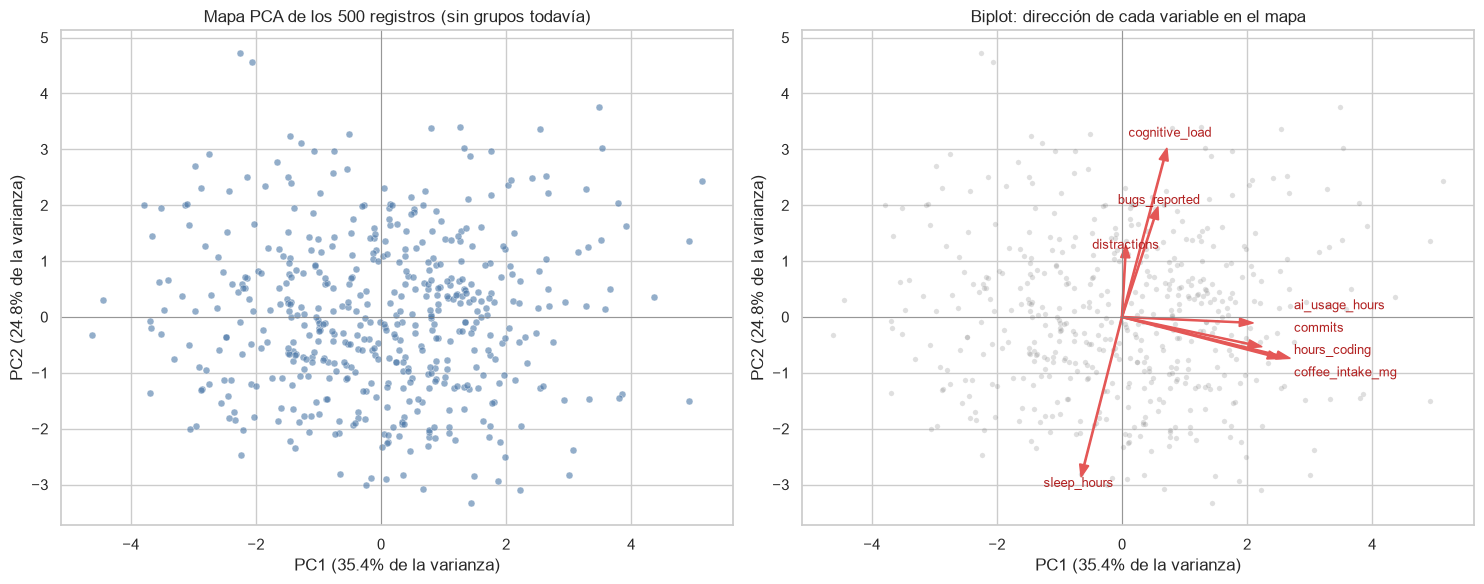

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Izquierda: mapa sin grupos
sns.scatterplot(data=mapa, x="PC1", y="PC2", s=25, alpha=0.6, color="#4C78A8", ax=axes[0])
axes[0].set_title("Mapa PCA de los 500 registros (sin grupos todavía)")

# Derecha: biplot (los loadings se amplían para que las flechas sean visibles)
ESCALA_FLECHAS = 4.5
sns.scatterplot(data=mapa, x="PC1", y="PC2", s=15, alpha=0.25, color="gray", ax=axes[1])
# Las cuatro variables de intensidad apuntan casi al mismo sitio: sus etiquetas se colocan a mano para que no se encimen
POS_ETIQUETA = {"ai_usage_hours": (2.75, 0.20), "commits": (2.75, -0.20), "hours_coding": (2.75, -0.60), "coffee_intake_mg": (2.75, -1.00)}
for variable, (c1, c2) in zip(VARIABLES, pca2.components_.T):
    axes[1].arrow(0, 0, c1 * ESCALA_FLECHAS, c2 * ESCALA_FLECHAS, color="#E45756", width=0.02, head_width=0.15)
    if variable in POS_ETIQUETA:
        axes[1].text(*POS_ETIQUETA[variable], variable, color="#B22222", ha="left", va="center", fontsize=9)
    else:
        axes[1].text(c1 * ESCALA_FLECHAS * 1.15, c2 * ESCALA_FLECHAS * 1.15, variable, color="#B22222", ha="center", fontsize=9)
axes[1].set_title("Biplot: dirección de cada variable en el mapa")

for ax in axes:
    ax.set_xlabel(f"PC1 ({var2[0]:.1%} de la varianza)")
    ax.set_ylabel(f"PC2 ({var2[1]:.1%} de la varianza)")
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
plt.tight_layout()
plt.show()

**Interpretación.**

- **Eje horizontal (PC1):** a la derecha están los registros de mayor intensidad de trabajo. Las flechas de hours_coding, coffee_intake_mg, commits y ai_usage_hours apuntan casi en la misma dirección, lo que confirma que miden un mismo factor.
- **Eje vertical (PC2):** arriba están los registros con más carga cognitiva y más bugs; abajo, los que duermen más. Las flechas de cognitive_load y sleep_hours apuntan en sentidos opuestos, reflejo de su correlación negativa.
- La flecha de distractions es la más corta: esa variable está mal representada en este plano.
- **Forma de la nube.** Los puntos forman una sola nube continua, más densa en el centro y más dispersa en los bordes. No se ven "islas" separadas por zonas vacías.

**Qué anticipa esto para el modelado:**

- K-Means siempre devuelve K grupos, así que dividirá esta nube en regiones. Es de esperar un coeficiente de Silhouette bajo, porque los grupos vecinos se tocan.
- DBSCAN une todo lo que está conectado por densidad. Con una nube continua es probable que encuentre un único grupo grande y marque como ruido los puntos dispersos de los bordes.

### 5.4 Decisión: ¿entrenar sobre las variables escaladas o sobre las componentes?

Antes de decidir, se mide cuánta información de cada variable conserva el plano PC1–PC2. Esa fracción se llama comunalidad: se calcula a partir de los loadings de la variable en las componentes que se conservan, y va de 0 % (la variable desaparece del mapa) a 100 % (se ve completa).

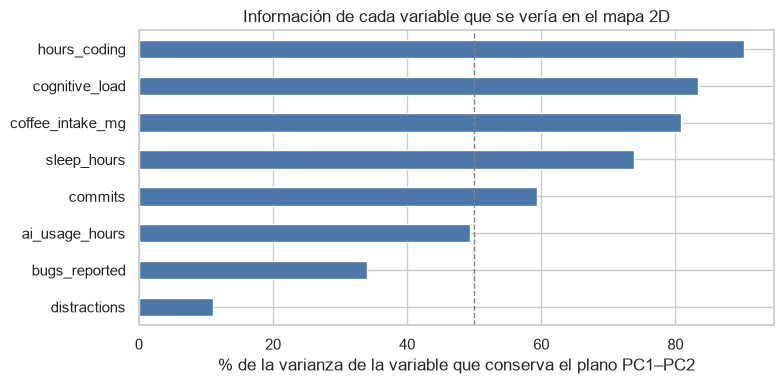

,conservada_con_2_PC,conservada_con_3_PC,conservada_con_5_PC
distractions,11.1,91.0,98.2
bugs_reported,34.0,51.9,99.8
ai_usage_hours,49.3,49.6,96.4
commits,59.4,59.4,74.4
sleep_hours,73.8,82.5,94.0
coffee_intake_mg,80.8,80.8,82.6
cognitive_load,83.4,88.2,93.2
hours_coding,90.2,90.3,90.8


In [25]:
lambdas = pca.explained_variance_                      # valores propios (varianza de cada componente)
comunalidad = pd.DataFrame({
    f"conservada_con_{m}_PC": (loadings.iloc[:, :m] ** 2 * lambdas[:m]).sum(axis=1) / X_esc.var(ddof=1)
    for m in (2, 3, 5)
}).sort_values("conservada_con_2_PC")

ax = (comunalidad["conservada_con_2_PC"] * 100).plot.barh(figsize=(8, 4), color="#4C78A8")
ax.axvline(50, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("% de la varianza de la variable que conserva el plano PC1–PC2")
ax.set_title("Información de cada variable que se vería en el mapa 2D")
plt.tight_layout()
plt.show()

(comunalidad * 100).round(1)

**Lectura.** El plano PC1–PC2 conserva bien las variables de intensidad (hours_coding, coffee_intake_mg) y el eje sueño–carga cognitiva, pero retiene muy poco de distractions y menos de la mitad de bugs_reported y ai_usage_hours. Entrenar en 2D equivaldría a segmentar casi sin mirar las distracciones, que solo se recuperan al añadir PC3.

| Opción | A favor | En contra |
|---|---|---|
| **8 variables escaladas** | No se pierde información. Los perfiles de cada segmento reflejan las 8 variables. La regla de min_samples de DBSCAN se aplica con D = 8, como en clase. | hours_coding y coffee_intake_mg pesan dos veces el mismo factor. En el mapa 2D los clusters pueden solaparse en los bordes, porque el gráfico solo muestra el 60 % de la varianza. |
| **2 componentes (PCA 2D)** | El mapa coincide exactamente con el espacio donde se forman los grupos. Elimina la redundancia entre variables. | Se descarta casi el 40 % de la varianza. distractions prácticamente desaparece, porque vive en PC3. |

**Decisión del equipo: los modelos se entrenan sobre las 8 variables escaladas y PCA se usa solo para visualizar.**

**Defensa de la decisión:**

1. **Información accionable.** Según la tabla de comunalidades, el plano 2D descarta casi toda la variación de distractions y buena parte de bugs_reported y ai_usage_hours. Son justamente las variables que llevan a acciones concretas (bloques de trabajo sin interrupciones, revisión de código, capacitación en IA). Un modelo entrenado en 2D no podría distinguir perfiles que solo difieren en esos hábitos.
2. **No hay un problema de dimensionalidad que resolver.** Con 500 registros y 8 variables hay más de 60 registros por dimensión. PCA como paso previo se justifica cuando hay decenas o cientos de variables, mucho ruido o distancias que dejan de discriminar; no es el caso.
3. **Un Silhouette más alto en 2D no es un argumento válido.** El coeficiente se calcula con distancias en el espacio donde se mide. Al eliminar dimensiones desaparece la variación que separa a los puntos dentro de cada grupo, y el Silhouette sube casi siempre. Comparar Silhouettes entre espacios distintos no indica cuál segmentación es mejor.
4. **Perfiles fieles.** Los segmentos se describen con el promedio de las 8 variables originales; conviene que el modelo haya usado esas mismas 8.
5. **Separación de responsabilidades en la app.** El segmento lo asigna el pipeline de 8 variables, y el PCA solo dibuja el mapa. Si un registro aparece en el mapa cerca de la frontera de otro grupo, se explica por el 40 % de varianza que el plano no muestra, no por un error del modelo.

**Costos que se asumen:** la redundancia entre hours_coding y coffee_intake_mg hace que el factor de intensidad pese algo más en la distancia euclidiana, y en el mapa 2D los grupos se solaparán en los bordes. En la sección 8.3 se comprueba la robustez de la decisión comparando la segmentación obtenida en ambos espacios.

## 6. Modelado con K-Means

K-Means divide los datos en K grupos asignando cada punto al centroide más cercano. Busca que la inercia, la suma de las distancias al cuadrado de cada punto a su centroide, sea lo más baja posible.

El algoritmo alterna dos pasos hasta que las asignaciones dejan de cambiar: (1) asignar cada punto al centroide más cercano y (2) recalcular cada centroide como el promedio de sus puntos. Los centroides iniciales se eligen con *k-means++*, y n_init=10 repite el proceso con 10 inicializaciones distintas y conserva la de menor inercia.

K no se aprende de los datos; se elige comparando dos criterios:

- **Método del codo.** La inercia siempre baja al aumentar K. Se busca el punto donde deja de bajar de forma marcada.
- **Coeficiente de Silhouette.** Compara, para cada punto, qué tan cerca está de su propio grupo frente al grupo vecino más cercano. Va de −1 a 1: un valor cercano a 1 indica un punto bien dentro de su grupo, cercano a 0 un punto en la frontera y negativo un punto que estaría mejor en otro grupo. El Silhouette del modelo es el promedio de todos los puntos.

### 6.1 Evaluación de K = 2 a 9

Cada modelo es un Pipeline (escalador + K-Means) entrenado sobre X en escala original. El Silhouette se calcula sobre los datos escalados, que es el espacio donde K-Means mide las distancias.

In [26]:
filas = []
for k in range(2, 10):                                               # K = 2 a 9
    modelo = Pipeline([("escalar", StandardScaler()),
                       ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=SEED))])
    etiquetas = modelo.fit_predict(X)                                # X sin escalar: el Pipeline escala
    tamanos = np.bincount(etiquetas)
    filas.append({"K": k,
                  "inercia": modelo.named_steps["kmeans"].inertia_,
                  "silhouette": silhouette_score(X_esc, etiquetas),
                  "grupo_mas_pequeno": tamanos.min(),
                  "grupo_mas_grande": tamanos.max()})

resultados_km = pd.DataFrame(filas).set_index("K")
resultados_km["caida_inercia"] = -resultados_km["inercia"].diff()   # cuánto baja la inercia al pasar de K-1 a K
resultados_km.round(4)

,inercia,silhouette,grupo_mas_pequeno,grupo_mas_grande,caida_inercia
K,,,,,
2,3072.9446,0.2023,221,279,NaN
3,2624.8886,0.1805,153,174,448.0560
4,2397.2106,0.1616,87,173,227.6781
5,2217.9016,0.1495,69,123,179.3090
6,2054.0881,0.1467,62,114,163.8136
7,1925.5725,0.1458,52,97,128.5155
8,1832.5906,0.1484,40,81,92.9820
9,1758.6075,0.1510,15,81,73.9831


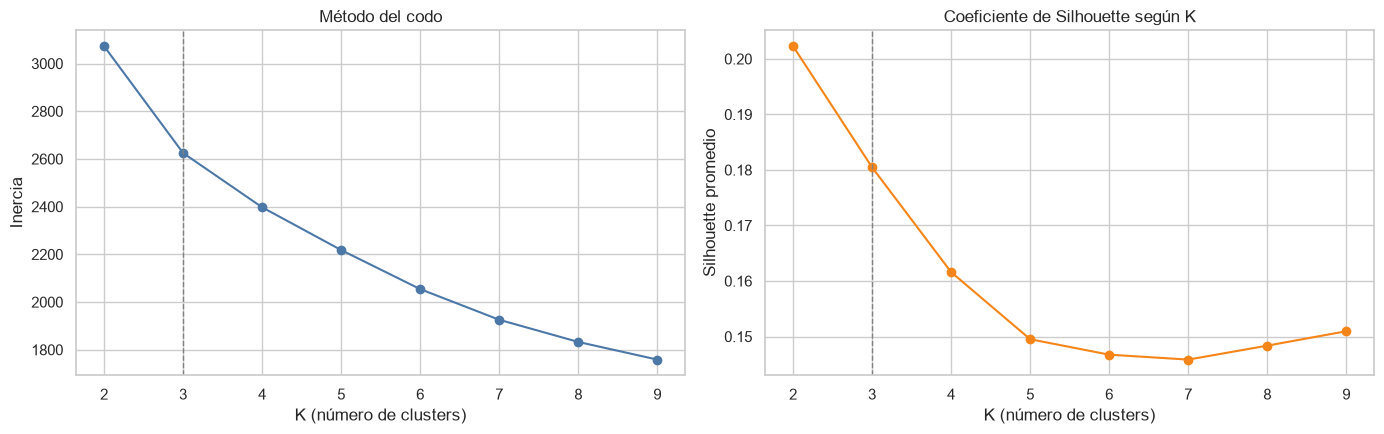

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(resultados_km.index, resultados_km["inercia"], marker="o", color="#4C78A8")
axes[0].set_title("Método del codo")
axes[0].set_ylabel("Inercia")

axes[1].plot(resultados_km.index, resultados_km["silhouette"], marker="o", color="#F58518")
axes[1].set_title("Coeficiente de Silhouette según K")
axes[1].set_ylabel("Silhouette promedio")

for ax in axes:
    ax.axvline(3, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("K (número de clusters)")
    ax.set_xticks(resultados_km.index)
plt.tight_layout()
plt.show()

**Lectura.**

- **Codo.** La mayor caída de inercia ocurre al pasar de K=2 a K=3; a partir de K=3 cada grupo adicional reduce la inercia cada vez menos. El codo no es nítido (la curva es suave), lo que es coherente con una nube continua, pero el cambio de pendiente más claro está en K=3.
- **Silhouette.** El máximo está en K=2 y K=3 queda muy cerca; desde K=4 el valor baja y se estanca. Todos los valores son bajos (alrededor de 0.15–0.20): los grupos existen como regiones de la nube, pero se tocan entre sí. Es lo que anticipaba el mapa PCA.

Como los dos criterios no coinciden del todo, se agregan dos comprobaciones antes de decidir: la estabilidad de cada partición y el Silhouette por punto.

### 6.2 Estabilidad de la partición

Una segmentación útil no debería cambiar si se repite el entrenamiento con otra semilla. Se entrena cada K con 10 semillas distintas y se compara cada resultado con el de la semilla 0 mediante el índice de Rand ajustado (ARI): vale 1 si las dos particiones son idénticas (aunque los números de cluster estén permutados) y cerca de 0 si coinciden solo por azar.

In [28]:
estabilidad = {}
for k in (2, 3, 4, 5):
    particiones = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X_esc) for s in range(10)]
    ari = [adjusted_rand_score(particiones[0], p) for p in particiones[1:]]
    estabilidad[k] = {"ARI_minimo": min(ari), "ARI_promedio": np.mean(ari)}

pd.DataFrame(estabilidad).T.rename_axis("K").round(3)

,ARI_minimo,ARI_promedio
K,,
2,0.968,0.996
3,0.954,0.977
4,0.484,0.780
5,0.340,0.558


**Lectura.** Con K=2 y K=3 las 10 semillas producen prácticamente la misma partición (ARI cercano a 1). Con K=4 el resultado depende de la semilla: K-Means encuentra soluciones distintas con inercias parecidas, señal de que el cuarto grupo no responde a una estructura real de los datos sino a una forma arbitraria de cortar la nube.

### 6.3 Silhouette por punto: K = 2 frente a K = 3

El promedio puede esconder diferencias. El diagrama de Silhouette muestra el valor de cada punto, agrupado por cluster y ordenado de mayor a menor.

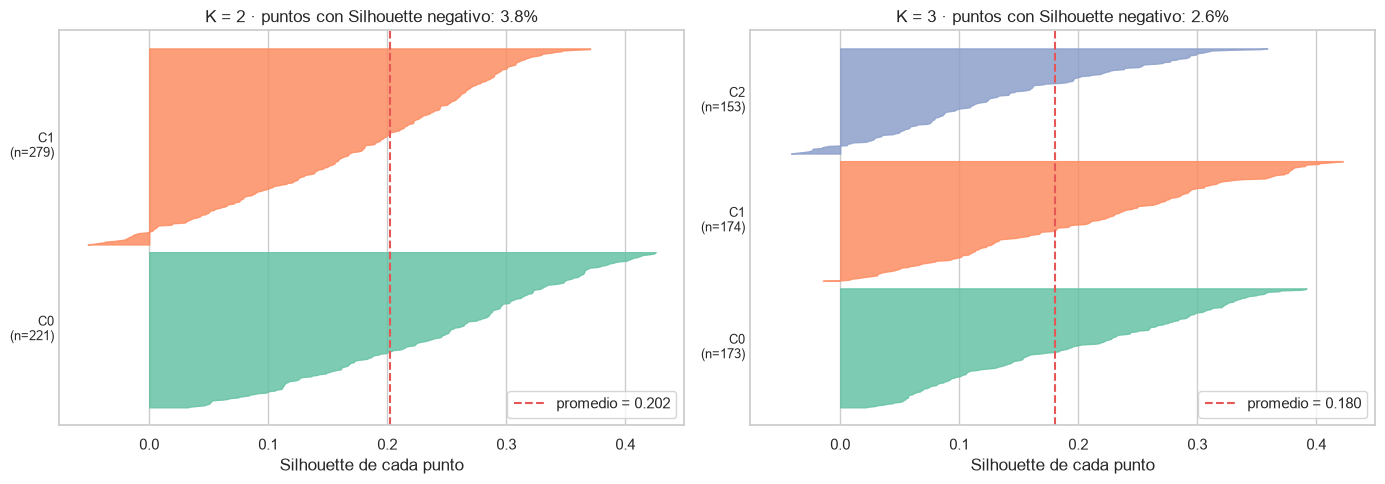

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
paleta = sns.color_palette("Set2")

for ax, k in zip(axes, (2, 3)):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_esc)
    s = silhouette_samples(X_esc, etiquetas)
    y = 0
    for c in range(k):
        valores = np.sort(s[etiquetas == c])
        ax.fill_betweenx(np.arange(y, y + len(valores)), 0, valores, color=paleta[c], alpha=0.85)
        ax.text(-0.08, y + len(valores) / 2, f"C{c}\n(n={len(valores)})", va="center", ha="right", fontsize=9)
        y += len(valores) + 10
    ax.axvline(s.mean(), color="#E45756", linestyle="--", label=f"promedio = {s.mean():.3f}")
    ax.set_title(f"K = {k} · puntos con Silhouette negativo: {(s < 0).mean():.1%}")
    ax.set_xlabel("Silhouette de cada punto")
    ax.set_yticks([])
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lectura.** En ambos casos los clusters tienen tamaños parecidos y ninguno está formado mayoritariamente por puntos mal asignados. La diferencia en el Silhouette promedio es pequeña, y K=3 incluso tiene menos puntos con valor negativo que K=2 (ver el título de cada gráfico): con K=2 hay más registros en la frontera que estarían mejor en el otro grupo, porque un único corte no separa bien a los intensivos desgastados de los poco activos.

### 6.4 Decisión sobre K

Se elige K = 3 (confirma la decisión D2 del plan):

| Criterio | K = 2 | K = 3 | K = 4 |
|---|---|---|---|
| Codo | Antes del codo | Cambio de pendiente más claro | Ganancia marginal |
| Silhouette promedio | Máximo | Muy cercano al máximo | Menor |
| Puntos con Silhouette negativo | Más | Menos | — |
| Estabilidad (ARI) | Alta | Alta | Baja: depende de la semilla |
| Utilidad para el negocio | Solo separa mucha de poca actividad | Separa a los intensivos según su nivel de desgaste | Grupo adicional inestable |

K=2 tiene un Silhouette ligeramente mayor, pero solo divide a los desarrolladores según su nivel de actividad (el eje PC1). K=3 mantiene casi la misma calidad de separación, es igual de estable y añade la distinción que permite actuar: dentro de los que trabajan mucho, quiénes lo hacen descansados y quiénes con desgaste. El costo que se asume es una pequeña pérdida de Silhouette a cambio de un segmento más que es accionable.

### 6.5 Modelo K-Means final

In [30]:
K_FINAL = 3

modelo_km = Pipeline([("escalar", StandardScaler()),
                      ("kmeans", KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED))])
df["kmeans"] = modelo_km.fit_predict(X)            # X sin escalar: el Pipeline escala

sil_km = silhouette_score(modelo_km[:-1].transform(X), df["kmeans"])
print("Registros por cluster:")
print(df["kmeans"].value_counts().sort_index().to_string())
print(f"\nInercia: {modelo_km.named_steps['kmeans'].inertia_:.1f} | Silhouette: {sil_km:.4f}")

Registros por cluster:
kmeans
0    173
1    174
2    153

Inercia: 2624.9 | Silhouette: 0.1805


Los perfiles de cada cluster, su nombre de negocio y la comparación con DBSCAN se desarrollan en las secciones 8 y 9.

## 7. Modelado con DBSCAN

DBSCAN agrupa por densidad. Depende de dos hiperparámetros:

- **eps (ε):** radio de la vecindad de cada punto.
- **min_samples (MinPts):** número mínimo de puntos dentro de ese radio, contando al propio punto, para que la zona se considere densa.

Con ellos clasifica cada registro en uno de tres tipos:

| Tipo | Definición |
|---|---|
| **Core** | Tiene al menos min_samples puntos a distancia ≤ ε |
| **Borde** | No es core, pero está a distancia ≤ ε de un punto core: pertenece a su cluster |
| **Ruido** (−1) | No es core ni está cerca de un core |

Un cluster es un conjunto de puntos core conectados entre sí (cada uno dentro del radio ε de otro) más sus puntos de borde. A diferencia de K-Means, DBSCAN no recibe el número de clusters, encuentra grupos de cualquier forma y separa explícitamente los valores atípicos.

### 7.1 Elección de min_samples

Regla práctica vista en clase: MinPts ≥ D + 1, con la sugerencia de usar 2·D, donde D es el número de variables con que se entrena.

In [31]:
D = X.shape[1]
MIN_SAMPLES = 2 * D
print(f"D = {D} variables -> mínimo permitido D + 1 = {D + 1} | valor elegido 2·D = {MIN_SAMPLES}")

D = 8 variables -> mínimo permitido D + 1 = 9 | valor elegido 2·D = 16


**Justificación.** Se usa el valor sugerido, min_samples = 16. En 8 dimensiones las distancias entre puntos tienden a parecerse más entre sí que en 2D, y un min_samples bajo convertiría en "zona densa" a cualquier pequeño grupo de puntos cercanos por azar. Duplicar D exige más evidencia de densidad antes de declarar un punto core, lo que hace al modelo más robusto frente al ruido. En la sección 7.4 se compara con el mínimo de la regla (min_samples = 9).

### 7.2 Elección de eps con el gráfico k-dist

Para cada punto se calcula la distancia a su vecino número min_samples. Si se ordenan esas distancias, la mayoría de los puntos (los que están en zonas densas) tienen valores pequeños y parecidos, y unos pocos (los aislados) valores grandes. El codo de esa curva marca el radio a partir del cual un punto deja de estar en zona densa: ese es eps.

**Detalle de implementación.** NearestNeighbors.kneighbors aplicado a los mismos datos con que se ajustó devuelve como primer vecino al propio punto (distancia 0). Por eso se usa n_neighbors = min_samples y la última columna: es exactamente el radio mínimo que necesita cada punto para ser core con min_samples = 16, porque DBSCAN también cuenta al propio punto.

Para no elegir el codo "a ojo", se localiza como el punto de la curva más alejado de la recta que une sus extremos, con ambos ejes normalizados a [0, 1].

In [32]:
vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_esc)
distancias, _ = vecinos.kneighbors(X_esc)
k_dist = np.sort(distancias[:, MIN_SAMPLES - 1])       # distancia al 16.º vecino (contando al propio punto), de menor a mayor


def indice_codo(curva):
    # Punto de una curva creciente más alejado de la recta que une sus extremos (ejes normalizados a [0, 1])
    x = np.linspace(0, 1, len(curva))
    y = (curva - curva.min()) / (curva.max() - curva.min())
    return int(np.argmax(x - y))


i_codo = indice_codo(k_dist)
EPS = round(float(k_dist[i_codo]), 2)
print(f"Codo en la posición {i_codo} de {len(k_dist)} (percentil {i_codo / len(k_dist):.0%}) -> eps = {EPS}")
print("Percentiles de la distancia k-dist:",
      {f"p{int(q * 100)}": round(float(np.quantile(k_dist, q)), 3) for q in (0.5, 0.75, 0.9, 0.95, 1.0)})

Codo en la posición 470 de 500 (percentil 94%) -> eps = 2.58
Percentiles de la distancia k-dist: {'p50': 1.816, 'p75': 2.072, 'p90': 2.466, 'p95': 2.674, 'p100': 4.898}


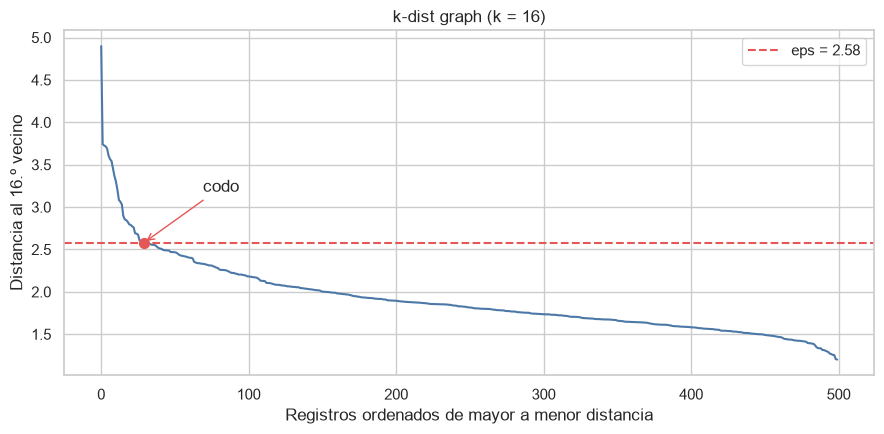

In [33]:
k_dist_desc = k_dist[::-1]                             # de mayor a menor, como en el taller de clase
pos_codo = len(k_dist) - 1 - i_codo

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(k_dist_desc, color="#4C78A8")
ax.axhline(EPS, color="#E45756", linestyle="--", label=f"eps = {EPS}")
ax.scatter([pos_codo], [EPS], color="#E45756", zorder=3, s=50)
ax.annotate("codo", (pos_codo, EPS), xytext=(pos_codo + 40, EPS + 0.6), arrowprops=dict(arrowstyle="->", color="#E45756"))
ax.set_title(f"k-dist graph (k = {MIN_SAMPLES})")
ax.set_xlabel("Registros ordenados de mayor a menor distancia")
ax.set_ylabel(f"Distancia al {MIN_SAMPLES}.º vecino")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.** La curva es casi plana para la gran mayoría de los registros y se dispara solo en el extremo izquierdo: unos pocos puntos están mucho más aislados que el resto. El codo queda cerca del percentil 94, lo que significa que con este eps alrededor del 94 % de los registros tiene su vecindario denso dentro del radio, es decir, que será punto core.

### 7.3 Modelo DBSCAN

In [34]:
modelo_db = Pipeline([("escalar", StandardScaler()),
                      ("dbscan", DBSCAN(eps=EPS, min_samples=MIN_SAMPLES))])
df["dbscan"] = modelo_db.fit_predict(X)            # X sin escalar: el Pipeline escala

dbscan = modelo_db.named_steps["dbscan"]
etiquetas_db = dbscan.labels_
n_clusters_db = len(set(etiquetas_db)) - (1 if -1 in etiquetas_db else 0)
es_core = np.zeros(len(df), dtype=bool)
es_core[dbscan.core_sample_indices_] = True
es_ruido = etiquetas_db == -1
es_borde = ~es_core & ~es_ruido

print(f"eps = {EPS} | min_samples = {MIN_SAMPLES}")
print(f"Clusters encontrados: {n_clusters_db}")
print(f"Puntos core: {es_core.sum()} | borde: {es_borde.sum()} | ruido: {es_ruido.sum()} ({es_ruido.mean():.1%})")
print("\nRegistros por grupo (−1 = ruido):")
print(df["dbscan"].value_counts().sort_index().to_string())


def silhouette_sin_ruido(X_escalado, etiquetas):
    # Silhouette excluyendo el ruido (−1); requiere al menos 2 clusters, si no, no está definido
    validos = etiquetas != -1
    if len(set(etiquetas[validos])) < 2:
        return np.nan
    return silhouette_score(X_escalado[validos], etiquetas[validos])


sil_db = silhouette_sin_ruido(X_esc.to_numpy(), etiquetas_db)
print("\nSilhouette sin ruido:", "no definido (hay menos de 2 clusters)" if np.isnan(sil_db) else round(sil_db, 4))

eps = 2.58 | min_samples = 16
Clusters encontrados: 1
Puntos core: 471 | borde: 24 | ruido: 5 (1.0%)

Registros por grupo (−1 = ruido):


dbscan
-1      5
 0    495

Silhouette sin ruido: no definido (hay menos de 2 clusters)


In [35]:
# ¿Por qué cada punto de ruido es atípico? Variable en la que más se aleja del promedio (en desviaciones estándar)
ruido = df.loc[es_ruido, VARIABLES + ["task_success"]].copy()
z_ruido = X_esc.loc[es_ruido]
ruido["variable_mas_extrema"] = z_ruido.abs().idxmax(axis=1)
ruido["z_de_esa_variable"] = [z_ruido.loc[i, v] for i, v in ruido["variable_mas_extrema"].items()]
ruido.round(2)

,hours_coding,coffee_intake_mg,distractions,sleep_hours,commits,bugs_reported,ai_usage_hours,cognitive_load,task_success,variable_mas_extrema,z_de_esa_variable
3,8.05,600,7,6.3,9,5,1.40,5.9,0,bugs_reported,3.76
145,6.56,600,1,5.7,10,5,3.92,4.7,0,bugs_reported,3.76
252,9.24,600,6,7.4,10,2,5.56,5.9,1,ai_usage_hours,3.73
378,9.38,600,7,7.5,8,0,4.67,6.8,1,ai_usage_hours,2.91
478,11.16,600,7,9.6,11,0,6.36,5.3,1,ai_usage_hours,4.47


**Lectura.**

- Con el eps del codo, DBSCAN encuentra un único cluster que contiene casi todos los registros, y marca como ruido a unos pocos puntos aislados.
- Con un solo cluster el coeficiente de Silhouette no está definido: el coeficiente compara cada punto con el grupo vecino más cercano, y aquí no hay otro grupo. No es un error del código, sino una consecuencia del resultado.
- Los puntos de ruido tienen al menos una variable muy alejada del promedio: son los perfiles extremos detectados en el EDA (sección 3.5).

### 7.4 Sensibilidad a eps y a min_samples

Para descartar que el resultado dependa de una mala elección de hiperparámetros, se repite DBSCAN con varios valores alrededor del codo y con el mínimo de la regla práctica (min_samples = D + 1 = 9).

In [36]:
filas = []
for ms in (D + 1, MIN_SAMPLES):
    for eps in (1.4, 1.6, 1.8, 2.0, 2.2, 2.4, EPS, 3.0):
        modelo = DBSCAN(eps=eps, min_samples=ms).fit(X_esc)
        lab = modelo.labels_
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        filas.append({"min_samples": ms, "eps": eps, "clusters": n_cl,
                      "pct_ruido": (lab == -1).mean() * 100,
                      "puntos_core": len(modelo.core_sample_indices_),
                      "silhouette_sin_ruido": silhouette_sin_ruido(X_esc.to_numpy(), lab),
                      "tamanos": np.bincount(lab[lab != -1]).tolist() if n_cl else []})

sensibilidad_db = pd.DataFrame(filas)
sensibilidad_db.round(3)

,min_samples,eps,clusters,pct_ruido,puntos_core,silhouette_sin_ruido,tamanos
0,9,1.40,3,47.6,90,0.102,"[224, 7, 31]"
1,9,1.60,2,20.4,237,0.254,"[390, 8]"
2,9,1.80,1,9.6,354,NaN,[452]
3,9,2.00,1,5.4,410,NaN,[473]
4,9,2.20,1,2.8,449,NaN,[486]
5,9,2.40,1,1.4,475,NaN,[493]
6,9,2.58,1,0.8,482,NaN,[496]
7,9,3.00,1,0.0,490,NaN,[500]
8,16,1.40,2,78.8,21,0.283,"[90, 16]"
9,16,1.60,1,33.6,113,NaN,[332]


**Interpretación.**

- En toda la zona razonable de eps (la región del codo y sus alrededores) DBSCAN devuelve un solo cluster y un porcentaje de ruido pequeño.
- Solo aparecen dos o más clusters con radios pequeños, y a costa de declarar ruido a una gran parte de los datos. Además, esos "clusters" son núcleos densos pequeños dentro de la misma nube, no grupos separados. No es una segmentación útil.
- El patrón se repite con min_samples = 9, de modo que no es un efecto de la regla elegida.

**Por qué ocurre.** DBSCAN une todos los puntos conectados por densidad. Como no existen zonas vacías entre los perfiles de desarrolladores (la nube es continua, como se vio en el mapa PCA y en las distribuciones sin varias "montañas"), toda la nube queda conectada en un solo grupo. El resultado es información sobre la forma de los datos, no un fallo de configuración: los perfiles cambian de forma gradual, sin fronteras naturales.

**Qué aporta DBSCAN al proyecto.** Aunque no sirve para segmentar este dataset, sí cumple bien otra función: identificar los registros que no se parecen a ningún vecindario denso. Por eso, según la decisión D4, la aplicación web usará K-Means para asignar el segmento y la regla de DBSCAN (punto core más cercano a distancia ≤ ε) para avisar cuando un registro nuevo sea atípico.

## 8. Evaluación y comparación de modelos

### 8.1 Tabla comparativa

Ambos modelos se evalúan en el mismo espacio: las 8 variables escaladas con el escalador del pipeline. En DBSCAN el Silhouette se calcula sin los puntos de ruido.

In [37]:
def resumen_modelo(nombre, etiquetas, X_escalado):
    etiquetas = np.asarray(etiquetas)
    n_cl = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    return {"modelo": nombre,
            "clusters": n_cl,
            "silhouette_sin_ruido": silhouette_sin_ruido(X_escalado, etiquetas),
            "pct_ruido": (etiquetas == -1).mean() * 100,
            "tamanos": pd.Series(etiquetas[etiquetas != -1]).value_counts().sort_index().tolist()}


X_modelo = modelo_km[:-1].transform(X)             # 8 variables escaladas con el escalador del pipeline final
comparacion = pd.DataFrame([
    resumen_modelo(f"K-Means (K = {K_FINAL})", df["kmeans"], X_modelo),
    resumen_modelo(f"DBSCAN (eps = {EPS}, min_samples = {MIN_SAMPLES})", df["dbscan"], X_modelo),
]).set_index("modelo")
comparacion["inercia"] = [modelo_km.named_steps["kmeans"].inertia_, np.nan]   # la inercia solo existe en K-Means
comparacion.round(4)

,clusters,silhouette_sin_ruido,pct_ruido,tamanos,inercia
modelo,,,,,
K-Means (K = 3),3,0.1805,0.0,"[173, 174, 153]",2624.8886
"DBSCAN (eps = 2.58, min_samples = 16)",1,NaN,1.0,[495],NaN


### 8.2 Ambos modelos sobre el mapa PCA

Los centroides de K-Means se proyectan en el mapa con el mismo PCA de la sección 5.3.

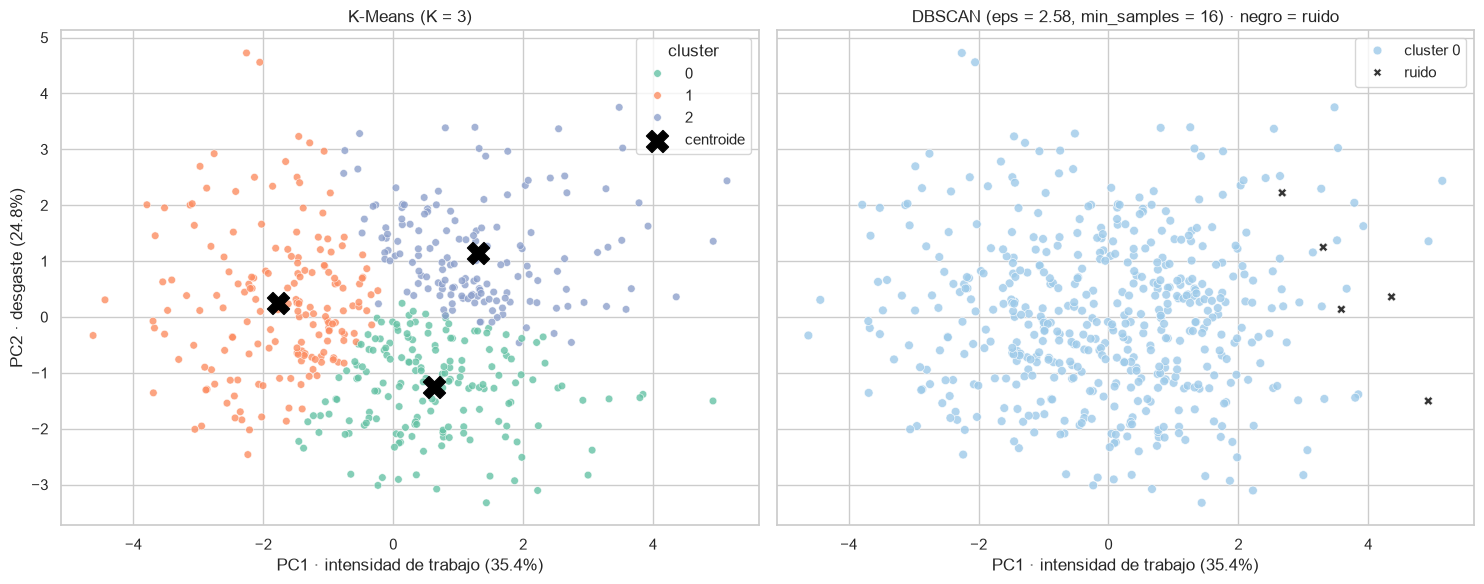

DBSCAN (−1 = ruido),-1,0
K-Means,,
0,1,172
1,0,174
2,4,149


In [38]:
mapa["kmeans"] = df["kmeans"].astype(str)
mapa["dbscan"] = np.where(df["dbscan"] == -1, "ruido", "cluster " + df["dbscan"].astype(str))
centroides_2d = pca2.transform(modelo_km.named_steps["kmeans"].cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="kmeans", hue_order=[str(k) for k in range(K_FINAL)],
                palette="Set2", s=30, alpha=0.8, ax=axes[0])
axes[0].scatter(centroides_2d[:, 0], centroides_2d[:, 1], marker="X", s=250, c="black", label="centroide")
axes[0].set_title(f"K-Means (K = {K_FINAL})")
axes[0].legend(title="cluster")

sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="dbscan", palette={"cluster 0": "#9ECAE9", "ruido": "black"},
                style="dbscan", markers={"cluster 0": "o", "ruido": "X"}, s=40, alpha=0.8, ax=axes[1])
axes[1].set_title(f"DBSCAN (eps = {EPS}, min_samples = {MIN_SAMPLES}) · negro = ruido")
axes[1].legend(title="")

for ax in axes:
    ax.set_xlabel(f"PC1 · intensidad de trabajo ({var2[0]:.1%})")
    ax.set_ylabel(f"PC2 · desgaste ({var2[1]:.1%})")
plt.tight_layout()
plt.show()

pd.crosstab(df["kmeans"], df["dbscan"], rownames=["K-Means"], colnames=["DBSCAN (−1 = ruido)"])

**Lectura.**

- K-Means divide la nube en tres regiones. Un grupo ocupa la izquierda del mapa (baja intensidad de trabajo). La mitad derecha (alta intensidad) se reparte en dos grupos separados por el eje vertical: uno abajo (poco desgaste) y otro arriba (mucho desgaste). En los bordes los colores se mezclan, porque el mapa solo muestra el 60 % de la varianza y la asignación se hizo con las 8 variables.
- DBSCAN pinta casi toda la nube de un solo color y marca como ruido unos pocos puntos en la periferia del mapa, del lado de alta intensidad.
- La tabla cruzada muestra que los puntos de ruido de DBSCAN están repartidos entre los clusters de K-Means: K-Means los asigna igualmente a un grupo, aunque estén lejos de su centroide.

### 8.3 Robustez de la decisión D1: ¿cambia la segmentación si se entrena en 2D?

Se entrena K-Means con K = 3 sobre las dos componentes del mapa y se compara con la partición obtenida sobre las 8 variables.

In [39]:
from itertools import permutations

km_2d = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit_predict(Z)
tabla_2d = pd.crosstab(df["kmeans"], km_2d, rownames=["K-Means en 8 variables"], colnames=["K-Means en PCA 2D"])

# Los números de cluster son arbitrarios: se busca la correspondencia entre ambos modelos que más registros hace coincidir
coinciden = max(sum(tabla_2d.values[i, p[i]] for i in range(K_FINAL)) for p in permutations(range(K_FINAL)))
print(f"Registros asignados al mismo grupo en ambos espacios: {coinciden} de {len(df)} ({coinciden / len(df):.1%})")
print(f"Índice de Rand ajustado (ARI): {adjusted_rand_score(df['kmeans'], km_2d):.3f}")
print(f"Silhouette en 2D: {silhouette_score(Z, km_2d):.4f} | Silhouette en 8 variables: {sil_km:.4f}")
tabla_2d

Registros asignados al mismo grupo en ambos espacios: 484 de 500 (96.8%)
Índice de Rand ajustado (ARI): 0.908
Silhouette en 2D: 0.3444 | Silhouette en 8 variables: 0.1805


K-Means en PCA 2D,0,1,2
K-Means en 8 variables,,,
0,161,2,10
1,0,174,0
2,1,3,149


**Lectura.** Las dos particiones coinciden en casi todos los registros: la estructura que encuentra K-Means vive casi entera en el plano PC1–PC2, así que la segmentación es robusta a la decisión D1. Las diferencias se concentran en registros de frontera.

El Silhouette en 2D es casi el doble que en 8 variables con prácticamente los mismos grupos. Es la prueba de lo que se dijo en la sección 5.4: el Silhouette sube al quitar dimensiones, no porque la segmentación mejore. Por eso no se usa para elegir el espacio de entrenamiento, y se mantiene la decisión de entrenar con las 8 variables.


### 8.4 Robustez frente a los outliers

En la sección 3.5 se decidió conservar los valores atípicos. Para comprobar que esa decisión no condiciona los resultados, se vuelve a entrenar K-Means con K = 3 en dos escenarios y se compara con el modelo final:

- sin los registros que tienen al menos un outlier según la regla IQR;
- sin los puntos que DBSCAN marcó como ruido.

Para cada escenario se mide cuántos registros quedan en el mismo grupo y cuánto se mueve como máximo un centroide, en desviaciones estándar de cada variable (0.1 equivale a un desplazamiento muy pequeño).

In [40]:
def comparar_sin(mascara, descripcion):
    # Reentrena K-Means sin los registros excluidos y lo compara con el modelo final
    modelo = Pipeline([("escalar", StandardScaler()),
                       ("kmeans", KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED))]).fit(X[mascara])
    etiquetas = modelo.predict(X[mascara])
    tabla = pd.crosstab(df.loc[mascara, "kmeans"], etiquetas).to_numpy()

    # Los números de cluster son arbitrarios: se busca la correspondencia que más registros hace coincidir
    mejor = max(permutations(range(K_FINAL)), key=lambda p: sum(tabla[i, p[i]] for i in range(K_FINAL)))
    coinciden = sum(tabla[i, mejor[i]] for i in range(K_FINAL))

    # Centroides de ambos modelos en escala original, emparejados por segmento
    c_final = modelo_km[0].inverse_transform(modelo_km[-1].cluster_centers_)
    c_nuevo = modelo[0].inverse_transform(modelo[-1].cluster_centers_)[list(mejor)]
    desplazamiento = (np.abs(c_nuevo - c_final) / X.std(ddof=0).to_numpy()).max()

    return {"escenario": descripcion,
            "registros_quitados": int((~mascara).sum()),
            "mismo_grupo": f"{coinciden} de {mascara.sum()} ({coinciden / mascara.sum():.1%})",
            "ARI": adjusted_rand_score(df.loc[mascara, "kmeans"], etiquetas),
            "max_desplazamiento_centroide": desplazamiento}


con_outlier = es_outlier.any(axis=1).to_numpy()
robustez = pd.DataFrame([
    comparar_sin(~con_outlier, f"Sin los {con_outlier.sum()} registros con algún outlier (IQR)"),
    comparar_sin(~es_ruido, f"Sin los {es_ruido.sum()} puntos de ruido de DBSCAN"),
]).set_index("escenario")
robustez.round(3)

,registros_quitados,mismo_grupo,ARI,max_desplazamiento_centroide
escenario,,,,
Sin los 30 registros con algún outlier (IQR),30,450 de 470 (95.7%),0.879,0.193
Sin los 5 puntos de ruido de DBSCAN,5,483 de 495 (97.6%),0.930,0.100


**Lectura.** En ambos escenarios casi todos los registros conservan su grupo y los centroides se mueven menos de una quinta parte de una desviación estándar. Los outliers sí desplazan un poco los centroides, como se anticipó en la sección 3.5, pero no cambian la segmentación ni el perfil de los segmentos. Eliminarlos no aportaría nada y sacaría de la muestra a perfiles reales, por lo que se confirma la decisión de conservarlos.

### 8.5 Elección del modelo final

| Criterio | K-Means (K = 3) | DBSCAN |
|---|---|---|
| Número de grupos | 3, de tamaños equilibrados | 1 grupo con casi todos los registros |
| Silhouette | Bajo pero medible | No definido (un solo cluster) |
| Ruido | No aplica: asigna todos los registros | Alrededor del 1 % |
| Estabilidad | Alta entre semillas | Sensible a eps: solo hay varios grupos con mucho ruido |
| Utilidad para el negocio | Tres perfiles con acciones distintas | No segmenta; sí identifica perfiles atípicos |

**Modelo final: K-Means con K = 3.** Es el único de los dos que produce una segmentación útil para la pregunta de negocio. DBSCAN no se descarta: su regla de puntos core se usará en la aplicación para avisar cuando un registro nuevo sea atípico (decisión D4).

## 9. Interpretación de los segmentos

### 9.1 Perfil de cada cluster en escala original

Se promedian las variables originales (sin escalar) de cada cluster. task_success se agrega recién ahora, después de entrenar: su promedio es la proporción de tareas exitosas del cluster y sirve para validar que los grupos tienen sentido, ya que el modelo nunca la vio.

In [41]:
perfiles = df.groupby("kmeans")[VARIABLES + ["task_success"]].mean()
perfiles["n_registros"] = df["kmeans"].value_counts().sort_index()
perfiles["pct_registros"] = perfiles["n_registros"] / len(df) * 100
perfiles["pct_cafe_en_tope"] = df.groupby("kmeans")["coffee_intake_mg"].apply(lambda s: (s == tope).mean() * 100)

promedio_global = df[VARIABLES + ["task_success"]].mean()
display(perfiles.round(2))
promedio_global.round(2).to_frame("promedio global").T

,hours_coding,coffee_intake_mg,distractions,sleep_hours,commits,bugs_reported,ai_usage_hours,cognitive_load,task_success,n_registros,pct_registros,pct_cafe_en_tope
kmeans,,,,,,,,,,,,
0,6.06,545.06,2.51,7.94,5.78,0.35,1.73,3.30,0.97,173,34.6,41.62
1,3.06,307.56,3.02,7.07,2.57,0.66,0.81,4.30,0.18,174,34.8,0.00
2,6.07,547.61,3.44,5.77,5.60,1.66,2.05,6.08,0.67,153,30.6,47.71


,hours_coding,coffee_intake_mg,distractions,sleep_hours,commits,bugs_reported,ai_usage_hours,cognitive_load,task_success
promedio global,5.02,463.19,2.98,6.98,4.61,0.86,1.51,4.5,0.61


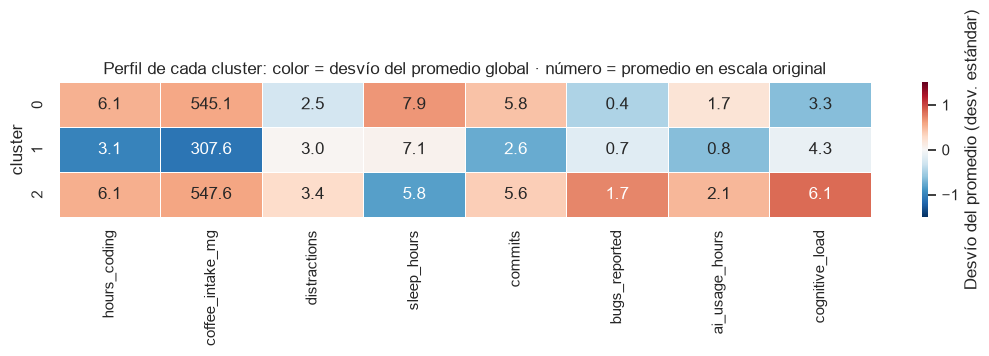

In [42]:
# Cuánto se aleja cada cluster del promedio global, en desviaciones estándar (0 = igual al promedio)
desvio = (perfiles[VARIABLES] - X.mean()) / X.std(ddof=0)

plt.figure(figsize=(11, 3.2))
sns.heatmap(desvio, annot=perfiles[VARIABLES].round(1), fmt="", cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5,
            linewidths=0.5, cbar_kws={"label": "Desvío del promedio (desv. estándar)"})
plt.title("Perfil de cada cluster: color = desvío del promedio global · número = promedio en escala original")
plt.ylabel("cluster")
plt.tight_layout()
plt.show()

**Lectura.**

- **Dos clusters trabajan igual de intensamente.** Tienen prácticamente las mismas horas de programación, la misma cafeína y un número parecido de commits y de horas de uso de IA, todo por encima del promedio. Se diferencian en el descanso: uno duerme más, tiene carga cognitiva baja y casi no reporta bugs; el otro duerme menos, soporta carga cognitiva alta, más distracciones y más bugs. Esa diferencia se refleja en la tasa de éxito, que es claramente menor en el grupo desgastado.
- **El tercer cluster trabaja mucho menos.** Tiene la mitad de horas de programación, menos cafeína, pocos commits y poco uso de IA. Su descanso y su carga cognitiva están en niveles medios, y su tasa de éxito es la más baja.
- **Validación externa.** task_success no participó en el entrenamiento y aun así varía mucho entre clusters. Es una señal de que la segmentación captura diferencias reales en los resultados del trabajo.
- **Cafeína.** Casi la mitad de los registros de cada cluster intensivo está en el tope de 600 mg (columna pct_cafe_en_tope), así que su promedio de cafeína es una cota inferior del consumo real (sección 3.4.1).

### 9.2 Nombre y acción recomendada por segmento

Los números de cluster que devuelve K-Means son arbitrarios: podrían cambiar con otra versión de la librería. Por eso los nombres se asignan con reglas sobre el perfil y no por número.

In [43]:
id_baja = perfiles["hours_coding"].idxmin()                   # el de menos horas de programación
intensivos = perfiles.drop(index=id_baja)
id_desgaste = intensivos["cognitive_load"].idxmax()            # entre los intensivos, el de más carga cognitiva
id_equilibrio = intensivos["cognitive_load"].idxmin()

SEGMENTOS = {
    int(id_equilibrio): {
        "nombre": "Intensivos en equilibrio",
        "color": "#009E73",
        "descripcion": "Jornadas largas y alta producción (más commits y uso de IA) con buen descanso, "
                       "carga cognitiva baja y pocos bugs. Es el segmento con mayor tasa de éxito.",
        "acciones": ["Mantener sus condiciones de trabajo y proteger su descanso.",
                     "Aprovecharlos como mentores: documentar y compartir cómo organizan la jornada y usan la IA."],
    },
    int(id_desgaste): {
        "nombre": "Intensivos en riesgo de desgaste",
        "color": "#D55E00",
        "descripcion": "Trabajan tantas horas como el segmento en equilibrio, pero duermen menos, soportan más "
                       "carga cognitiva y distracciones y reportan más bugs. Su tasa de éxito es menor.",
        "acciones": ["Revisar carga y plazos, y priorizar tareas para bajar la carga cognitiva.",
                     "Proteger el descanso y reservar bloques de concentración sin interrupciones.",
                     "Revisión de código en pareja para contener los bugs."],
    },
    int(id_baja): {
        "nombre": "Baja actividad",
        "color": "#0072B2",
        "descripcion": "Pocas horas de programación, pocos commits y poco uso de IA, con descanso y carga "
                       "cognitiva en niveles medios. Es el segmento con menor tasa de éxito.",
        "acciones": ["Diagnosticar bloqueos: tareas poco claras, dependencias externas o falta de onboarding.",
                     "Acompañamiento cercano y capacitación en herramientas de IA."],
    },
}

df["segmento"] = df["kmeans"].map(lambda c: SEGMENTOS[c]["nombre"])
resumen_segmentos = pd.DataFrame({
    "segmento": [SEGMENTOS[c]["nombre"] for c in perfiles.index],
    "registros": perfiles["n_registros"],
    "pct_exito": (perfiles["task_success"] * 100).round(1),
    "accion_principal": [SEGMENTOS[c]["acciones"][0] for c in perfiles.index],
}, index=perfiles.index)
resumen_segmentos

,segmento,registros,pct_exito,accion_principal
kmeans,,,,
0,Intensivos en equilibrio,173,97.1,Mantener sus condiciones de trabajo y proteger...
1,Baja actividad,174,18.4,"Diagnosticar bloqueos: tareas poco claras, dep..."
2,Intensivos en riesgo de desgaste,153,67.3,"Revisar carga y plazos, y priorizar tareas par..."


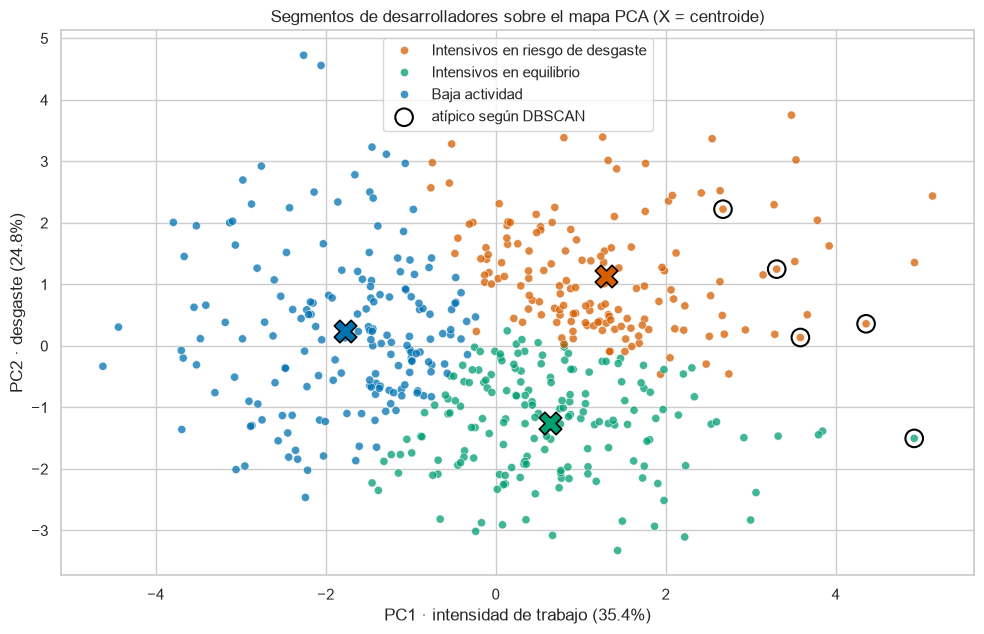

In [44]:
COLORES = {s["nombre"]: s["color"] for s in SEGMENTOS.values()}

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(x=mapa["PC1"], y=mapa["PC2"], hue=df["segmento"], palette=COLORES, s=35, alpha=0.75, ax=ax)
for c, (x, y) in enumerate(centroides_2d):
    ax.scatter(x, y, marker="X", s=260, c=SEGMENTOS[c]["color"], edgecolors="black", linewidths=1.2)
ax.scatter(mapa.loc[es_ruido, "PC1"], mapa.loc[es_ruido, "PC2"], facecolors="none", edgecolors="black", s=160,
           linewidths=1.5, label="atípico según DBSCAN")
ax.set_xlabel(f"PC1 · intensidad de trabajo ({var2[0]:.1%})")
ax.set_ylabel(f"PC2 · desgaste ({var2[1]:.1%})")
ax.set_title("Segmentos de desarrolladores sobre el mapa PCA (X = centroide)")
ax.legend(title="")
plt.tight_layout()
plt.show()

**Lectura.** El mapa resume la segmentación en los dos ejes del PCA: a la izquierda los desarrolladores de baja actividad; a la derecha los intensivos, divididos por el eje de desgaste en equilibrio (abajo) y riesgo de desgaste (arriba). Los círculos negros son los registros que DBSCAN considera atípicos: tienen segmento asignado, pero su perfil se aleja de cualquier zona densa de datos. Este es el gráfico que reproducirá la aplicación web, con el registro nuevo resaltado.

## 10. Entrenamiento final y exportación

En clustering no hay división entrenamiento/prueba: el modelo final ya está entrenado con el 100 % de los datos (los 500 registros) en la sección 6.5. Ahora se empaqueta en un único archivo todo lo que la aplicación necesita para asignar un registro nuevo sin volver a entrenar nada:

| Elemento | Para qué lo usa la app |
|---|---|
| pipeline | Escalar el registro nuevo y asignarle un segmento con K-Means |
| pca_2d | Ubicar el registro en el mapa, con el mismo sistema de coordenadas de los 500 históricos |
| detector_atipicos | Aplicar la regla de DBSCAN: si el punto core más cercano está a más de eps, el registro es atípico |
| features y rangos | Construir el formulario con las columnas, el orden y los límites del entrenamiento |
| segmentos y perfiles | Mostrar el nombre, la descripción, las acciones y el perfil promedio del segmento |
| historico_2d | Dibujar los 500 puntos coloreados por segmento |
| meta | Trazabilidad: versión de scikit-learn, fecha, métricas |

### 10.1 Piezas del artefacto

In [45]:
import joblib
from datetime import datetime

# PCA para el mapa, ajustado sobre la salida del escalador del pipeline final (mismo sistema de coordenadas)
pca_2d = PCA(n_components=2, random_state=SEED).fit(X_modelo)
coordenadas = pca_2d.transform(X_modelo)
assert np.allclose(coordenadas, Z), "El mapa exportado debe coincidir con el de la sección 5.3"

# Regla de clase para DBSCAN: vecino más cercano entre los puntos core
nn_core = NearestNeighbors(n_neighbors=1).fit(dbscan.components_)
distancia_core, _ = nn_core.kneighbors(modelo_db[:-1].transform(X))
regla_atipico = distancia_core[:, 0] > EPS
print("La regla reproduce exactamente el ruido de DBSCAN en los 500 registros:", np.array_equal(regla_atipico, es_ruido))

historico_2d = pd.DataFrame({"PC1": coordenadas[:, 0], "PC2": coordenadas[:, 1],
                             "cluster": df["kmeans"], "segmento": df["segmento"], "atipico": es_ruido})

ENTEROS = ["distractions", "commits", "bugs_reported"]
rangos = {v: {"min": float(X[v].min()), "max": float(X[v].max()), "mediana": float(X[v].median()),
              "entero": v in ENTEROS} for v in VARIABLES}
pd.DataFrame(rangos).T

La regla reproduce exactamente el ruido de DBSCAN en los 500 registros: True


,min,max,mediana,entero
hours_coding,0.0,12.0,5.03,False
coffee_intake_mg,6.0,600.0,500.5,False
distractions,0.0,8.0,3.0,True
sleep_hours,3.0,10.0,6.95,False
commits,0.0,13.0,5.0,True
bugs_reported,0.0,5.0,0.0,True
ai_usage_hours,0.0,6.36,1.26,False
cognitive_load,1.0,10.0,4.4,False


In [46]:
artefacto = {
    "pipeline": modelo_km,                       # StandardScaler + KMeans(K=3), entrenado con el 100 % de los datos
    "pca_2d": pca_2d,
    "detector_atipicos": {
        "pipeline_dbscan": modelo_db,            # StandardScaler + DBSCAN, para transformar el registro en su mismo espacio
        "nn_core": nn_core,                      # NearestNeighbors(n_neighbors=1) sobre dbscan.components_
        "etiquetas_core": dbscan.labels_[dbscan.core_sample_indices_],
        "eps": EPS,
        "min_samples": MIN_SAMPLES,
    },
    "features": VARIABLES,
    "rangos": rangos,
    "segmentos": SEGMENTOS,
    "perfiles": perfiles,
    "promedio_global": promedio_global,
    "historico_2d": historico_2d,
    "varianza_pca": pca_2d.explained_variance_ratio_.tolist(),
    "meta": {
        "modelo": "KMeans", "k": K_FINAL, "silhouette": float(sil_km),
        "inercia": float(modelo_km.named_steps["kmeans"].inertia_),
        "n_registros": len(df), "seed": SEED,
        "sklearn_version": sklearn.__version__, "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
    },
}

RUTA_MODELOS = RUTA_DATOS.parent.parent / "models"
RUTA_MODELOS.mkdir(exist_ok=True)
RUTA_MODELO = RUTA_MODELOS / "modelo_clustering.pkl"
joblib.dump(artefacto, RUTA_MODELO, compress=3)
print(f"Modelo exportado en {RUTA_MODELO.resolve()} ({RUTA_MODELO.stat().st_size / 1024:.0f} KB)")

Modelo exportado en C:\Proyectos\IARECURSOSRDA2\PROYECTORDA2\models\modelo_clustering.pkl (33 KB)


### 10.2 Prueba de carga y asignación de registros nuevos

Se recarga el archivo desde disco, como lo hará la aplicación, y se asignan cuatro registros de ejemplo. La función asignar aplica la misma secuencia que usará la app: armar un DataFrame con las columnas del entrenamiento, predecir con el pipeline, proyectar en el mapa y aplicar la regla de atípicos.

In [47]:
art = joblib.load(RUTA_MODELO)


def asignar(registro, art):
    entrada = pd.DataFrame([registro], columns=art["features"])          # mismas columnas y mismo orden
    cluster = int(art["pipeline"].predict(entrada)[0])                  # escala con el escalador ajustado y asigna
    pc1, pc2 = art["pca_2d"].transform(art["pipeline"][:-1].transform(entrada))[0]
    detector = art["detector_atipicos"]
    distancia = detector["nn_core"].kneighbors(detector["pipeline_dbscan"][:-1].transform(entrada))[0][0, 0]
    return {"cluster": cluster, "segmento": art["segmentos"][cluster]["nombre"],
            "atipico": bool(distancia > detector["eps"]), "distancia_core": round(float(distancia), 2),
            "PC1": round(float(pc1), 2), "PC2": round(float(pc2), 2)}


EJEMPLOS = {
    "A · jornada larga y descansada": dict(hours_coding=6.5, coffee_intake_mg=560, distractions=2, sleep_hours=8.2,
                                          commits=6, bugs_reported=0, ai_usage_hours=1.8, cognitive_load=3.0),
    "B · jornada larga con poco sueño": dict(hours_coding=6.2, coffee_intake_mg=550, distractions=4, sleep_hours=5.5,
                                            commits=5, bugs_reported=2, ai_usage_hours=2.0, cognitive_load=6.5),
    "C · jornada corta": dict(hours_coding=2.8, coffee_intake_mg=280, distractions=3, sleep_hours=7.0,
                              commits=2, bugs_reported=1, ai_usage_hours=0.7, cognitive_load=4.3),
    "D · perfil extremo": dict(hours_coding=11.0, coffee_intake_mg=600, distractions=8, sleep_hours=3.5,
                               commits=13, bugs_reported=5, ai_usage_hours=6.0, cognitive_load=9.5),
}
pruebas = pd.DataFrame({nombre: asignar(r, art) for nombre, r in EJEMPLOS.items()}).T
pruebas

,cluster,segmento,atipico,distancia_core,PC1,PC2
A · jornada larga y descansada,0,Intensivos en equilibrio,False,0.96,0.79,-1.72
B · jornada larga con poco sueño,2,Intensivos en riesgo de desgaste,False,1.0,1.32,1.6
C · jornada corta,1,Baja actividad,False,0.95,-2.04,0.46
D · perfil extremo,2,Intensivos en riesgo de desgaste,True,5.1,6.49,4.22


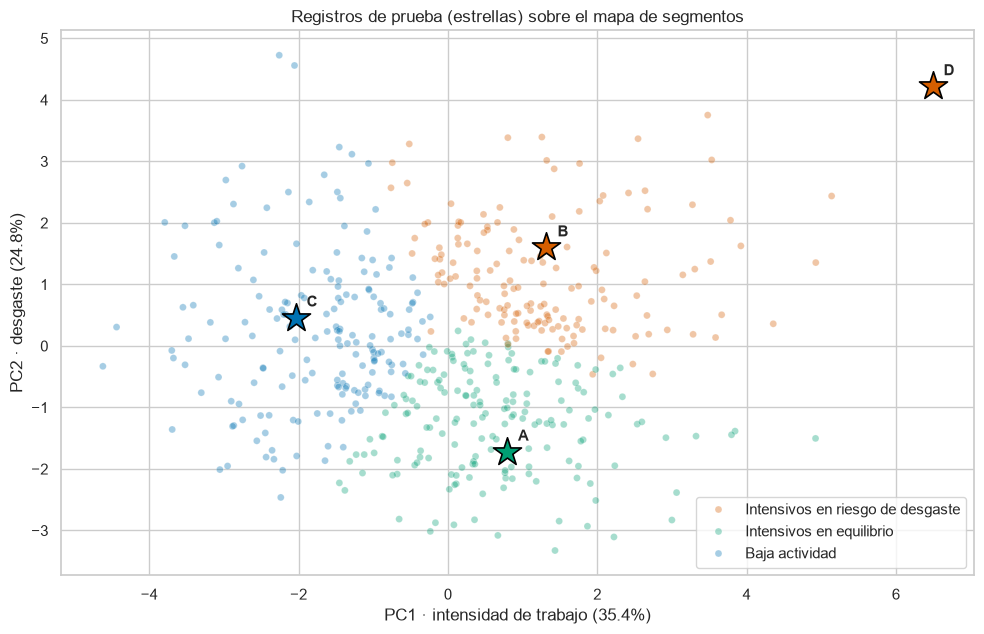

In [48]:
fig, ax = plt.subplots(figsize=(10, 6.5))
h = art["historico_2d"]
sns.scatterplot(data=h, x="PC1", y="PC2", hue="segmento", palette=COLORES, s=25, alpha=0.35, ax=ax)
for nombre, fila in pruebas.iterrows():
    ax.scatter(fila["PC1"], fila["PC2"], marker="*", s=450, c=COLORES[fila["segmento"]], edgecolors="black", linewidths=1.2, zorder=3)
    ax.annotate(nombre.split(" · ")[0], (fila["PC1"], fila["PC2"]), xytext=(8, 8), textcoords="offset points",
                fontsize=11, weight="bold")
ax.set_xlabel(f"PC1 · intensidad de trabajo ({art['varianza_pca'][0]:.1%})")
ax.set_ylabel(f"PC2 · desgaste ({art['varianza_pca'][1]:.1%})")
ax.set_title("Registros de prueba (estrellas) sobre el mapa de segmentos")
ax.legend(title="")
plt.tight_layout()
plt.show()

**Lectura.** El archivo exportado se recarga sin errores y asigna los tres primeros registros a segmentos distintos, coherentes con su perfil. El registro D recibe un segmento (K-Means siempre asigna uno), pero la regla de DBSCAN lo marca como atípico porque su punto core más cercano está mucho más lejos que eps: la aplicación mostrará ese aviso para indicar que la asignación es menos fiable.

Las métricas que respaldan el modelo son las de las secciones 6 a 8. Al entrenar con el 100 % de los datos no queda un conjunto independiente con el que volver a medir, algo propio del aprendizaje no supervisado.

## 11. Conclusiones y limitaciones

**Conclusiones**

- Los 500 registros forman una nube continua organizada en dos ejes: la intensidad de trabajo (horas, cafeína, commits, uso de IA) y el desgaste (poco sueño, carga cognitiva alta, bugs).
- K-Means con K = 3 identifica tres segmentos accionables: intensivos en equilibrio, intensivos en riesgo de desgaste y baja actividad. Su tasa de éxito difiere mucho entre segmentos, aunque esa variable no se usó para entrenar.
- DBSCAN no encuentra grupos separados por densidad, lo que confirma que los perfiles cambian de forma gradual. Se aprovecha como detector de registros atípicos.

**Limitaciones**

1. **Segmentos sobre un continuo.** El Silhouette es bajo: los segmentos son regiones de una nube sin fronteras naturales, y los registros cercanos a una frontera podrían pertenecer a cualquiera de los dos grupos vecinos.
2. **Cafeína censurada en 600 mg.** El perfil de cafeína de los segmentos intensivos es una cota inferior, y la app no admite valores superiores a 600 mg.
3. **Alcance del dataset.** 500 registros de una sola fuente, sin información de contexto (tipo de proyecto, experiencia, rol). Los segmentos describen esta muestra y no deben usarse para evaluar el desempeño individual de una persona.